In [1]:

# phase cluster - 0:transition, 1:lag, 2:stationary, 3:log
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
from scipy.io import loadmat
from datetime import datetime
import seaborn as sns
import matplotlib.ticker as ticker
from sklearn.preprocessing import MinMaxScaler
import statsmodels.api as sm
from scipy.interpolate import interp1d
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import random
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, LabelEncoder
import torch.nn as nn
import torch.nn.functional as F
import torch
import torch.optim as optim
from itertools import product
from torch.utils.data import DataLoader, TensorDataset, random_split
from sklearn.metrics import mean_squared_error
import joblib
import math
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from copy import deepcopy
from torch.optim.lr_scheduler import StepLR
from torch.optim.lr_scheduler import ReduceLROnPlateau
import warnings
import pickle
from datetime import datetime, timedelta
from scipy.integrate import solve_ivp
warnings.simplefilter(action='ignore', category=pd.errors.SettingWithCopyWarning)
warnings.filterwarnings(
    "ignore",
    message="X does not have valid feature names, but RandomForestClassifier was fitted with feature names",
    category=UserWarning,
)
warnings.filterwarnings(
    "ignore",
    message="X does not have valid feature names, but OneHotEncoder was fitted with feature names",
    category=UserWarning,
)
datapath = r'C:\Research\HybridModel\March2025\Data'
modelpath = r'C:\Research\HybridModel\March2025\Model'
rf = joblib.load(os.path.join(modelpath, 'random_forest_phase_model_noco2_v3.pkl'))

class LSTMModelwFutureU(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, n_steps_out, 
                 u_future_size=1, bidirectional=False, num_layers=1, dropout=0.0, dropout_input=0.0, init_method="xavier"):
        super(LSTMModelwFutureU, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, 
                            dropout=dropout, bidirectional=bidirectional)
        
        self.n_steps_out = n_steps_out
        self.output_size = output_size
        self.bidirectional = bidirectional
        self.hidden_size = hidden_size
        self.u_future_size = u_future_size
        self.in_drop = nn.Dropout(dropout_input)
        
        # Fully connected layer input: LSTM output + flattened future controls
        fc_input_size = hidden_size * (2 if bidirectional else 1) + n_steps_out * u_future_size
        self.fc = nn.Linear(fc_input_size, output_size * n_steps_out)

        self.init_weights(init_method)

    def init_weights(self, init_method):
        for name, param in self.lstm.named_parameters():
            if 'weight' in name:
                if init_method == 'xavier':
                    nn.init.xavier_uniform_(param)
                elif init_method == 'he':
                    nn.init.kaiming_uniform_(param, nonlinearity='relu')
                elif init_method == 'normal':
                    nn.init.normal_(param, mean=0.0, std=0.02)
                elif init_method == 'constant':
                    nn.init.constant_(param, 1e-4)
            elif 'bias' in name:
                nn.init.constant_(param, 0.0)

        if init_method == 'xavier':
            nn.init.xavier_uniform_(self.fc.weight)
        elif init_method == 'he':
            nn.init.kaiming_uniform_(self.fc.weight, nonlinearity='relu')
        elif init_method == 'normal':
            nn.init.normal_(self.fc.weight, mean=0.0, std=0.02)
        elif init_method == 'constant':
            nn.init.constant_(self.fc.weight, 1e-4)

        nn.init.constant_(self.fc.bias, 0.0)

    def forward(self, x, u_future):
        """
        x: shape (batch_size, n_steps_in, input_size)
        u_future: shape (batch_size, n_steps_out, u_future_size)
        """
        x = self.in_drop(x)
        lstm_out, _ = self.lstm(x)
        last_hidden = lstm_out[:, -1, :]  # (batch_size, hidden_size)
        u_flat = u_future.view(u_future.size(0), -1)  # (batch_size, n_steps_out * u_future_size)

        combined = torch.cat([last_hidden, u_flat], dim=1)  # (batch_size, fc_input_size)
        out = self.fc(combined)
        return out.view(-1, self.n_steps_out, self.output_size)
    
class WeightedMSELoss(nn.Module):
    def __init__(self, weights):
        super(WeightedMSELoss, self).__init__()
        self.weights = torch.tensor(weights, dtype=torch.float32)

    def forward(self, y_pred, y_true):
        loss_per_output = (y_pred - y_true) ** 2  # shape: [batch, 3]
        weighted_loss = loss_per_output * self.weights  # shape: [batch, 3]
        return weighted_loss.mean()
    
def safe_divide_np(numerator, denominator):
    return np.nan if denominator == 0 or np.isnan(denominator) else numerator / denominator

In [ ]:
## Training data
###Time  freq to keep data
t_freq = 60

data_stack = pd.read_csv(os.path.join(datapath, "stacked_experiment_data_w_phasecluster.csv"))
data_stack['experiment_id'] = data_stack['year'].astype(str) + '_W' + data_stack['week'].astype(str).str.zfill(2) + '_' + data_stack['reactor']

data_stack = data_stack[['ProcTime', 'AirFlow', 'ExitCO2',
       'ExitO2', 'OD', 'pO2', 'Stirrer', 'Weight_In', 'Weight_Out',
       'Pump_Val_Acid', 'Pump_Val_Base', 'pH', 'ExitCO2_adjust', 'pO2_adjust',
       'pH_scale', 'Pump_Val_Acid_adj', 'Pump_Val_Base_adj',
       'Pump_Val_Acid_diff_bin', 'Pump_Val_Base_diff_bin', 'Substrate',
       'Timestamp', 'Substrate_AEKF', 'Substrate_EKF', 'year', 'week',
       'reactor', 'Sin', 'CO2_adjust', 'pO2_adjust_ratio', 'ExitCO2_smoother',
       'pO2_smoother', 'Weight_In2', 'experiment_id', 'OD_change_rate_smooth','cluster']]

data_stack['pO2_adjust_fit'] = 80.543 + 0.0030234 * data_stack['Stirrer'] + 2.1573 * data_stack['AirFlow']
data_stack['pO2_adjust_fit'] = data_stack['pO2_adjust_fit'].rolling(window=50, center=True, min_periods=1).mean()
data_stack.loc[data_stack['experiment_id'] == '2024_W51_B2', 'Substrate'] = data_stack.loc[data_stack['experiment_id'] == '2024_W51_B2', 'Substrate_AEKF']
target_ids = ['2025_W21_A2', '2025_W21_B2']
mask = data_stack['experiment_id'].isin(target_ids)
data_stack['newOD']  = np.nan
data_stack.loc[mask, 'newOD'] = data_stack.loc[mask, 'OD']
data_stack['CDW']  = np.nan
a, b = 12.196, 2.1023
data_stack.loc[mask, 'CDW'] = a * data_stack.loc[mask, 'newOD'] + b

def invert_cdw_to_old_od(cdw_vals):
    cdw_vals = np.array(cdw_vals)
    OD_vals = np.zeros_like(cdw_vals)

    # Invert upper segment: CDW = 22.187 * OD - 5.0991 → OD = (CDW + 5.0991) / 22.187
    high_mask = cdw_vals >= (22.187 * 0.5207 - 5.0991)
    OD_vals[high_mask] = (cdw_vals[high_mask] + 5.0991) / 22.187

    # Invert lower segment: CDW = 11.124 * OD + 0.66116 → OD = (CDW - 0.66116) / 11.124
    low_mask = ~high_mask
    OD_vals[low_mask] = (cdw_vals[low_mask] - 0.66116) / 11.124

    return OD_vals

cdw_values = data_stack.loc[mask, 'CDW']
data_stack.loc[mask, 'OD'] = invert_cdw_to_old_od(cdw_values)

# data_stack = data_stack.loc[~data_stack['experiment_id'].isin(['2025_W14_B2', '2024_W51_A2', '2024_W51_B2', '2024_W43_A2', '2024_W43_B2']), :]
# data_stack = data_stack.loc[~data_stack['experiment_id'].isin(['2025_W14_B2', '2024_W51_A2', '2024_W51_B2', '2024_W48_A2']), :]
data_stack = data_stack.loc[~data_stack['experiment_id'].isin(['2024_W51_A2', '2024_W51_B2', '2024_W43_A2', '2024_W43_B2', '2025_W21_A2', '2025_W21_B2', '2025_W23_A2', '2025_W23_B2', '2024_W49_B2']), :]
print(data_stack.columns)
print(data_stack.head(5))
print(data_stack['experiment_id'].unique())

##Scale each experiment ExitCO2 between 0.04 and 1, Scale W10_A2 pO2 range to be same as W10_B2

def scale_within_group(series, new_min=0.04, new_max=1.0):
    min_val = series.min()
    max_val = series.max()
    if min_val == max_val:
        return pd.Series([new_min] * len(series), index=series.index)  # Handle constant values
    scaled = (series - min_val) / (max_val - min_val)
    return scaled * (new_max - new_min) + new_min

# Apply scaling group-wise
data_stack['ExitCO2_adjust_scaled1'] = (
    data_stack.groupby('experiment_id')['ExitCO2_adjust']
    .transform(lambda x: scale_within_group(x, 0.04, 1))
)

target_exp = '2025_W10_B2'
target_min = data_stack.loc[data_stack['experiment_id'] == target_exp, 'pO2_adjust'].min()
target_max = data_stack.loc[data_stack['experiment_id'] == target_exp, 'pO2_adjust'].max()

def scale_to_target_range(series, tmin, tmax):
    src_min, src_max = series.min(), series.max()
    if src_min == src_max:
        return pd.Series(tmin, index=series.index)
    scaled = (series - src_min) / (src_max - src_min)
    return scaled * (tmax - tmin) + tmin

# 1) Copy original values as default
data_stack['pO2_adjust_scaled1'] = data_stack['pO2_adjust']

# 2) Compute scaled only for the target experiment
mask = data_stack['experiment_id'] == target_exp
scaled = scale_to_target_range(
    data_stack.loc[mask, 'pO2_adjust'],
    target_min,
    target_max
)

# 3) Assign back
data_stack.loc[mask, 'pO2_adjust_scaled1'] = scaled
print(data_stack.loc[mask, 'pO2_adjust_scaled1'].head(10))
print(data_stack.loc[~mask, 'pO2_adjust_scaled1'].head(10))
## Process data for state prediction

data_for_scale_st = data_stack.loc[data_stack['ProcTime'] % t_freq == 0 , ['ProcTime', 'OD', 'Substrate', 'Weight_In', 'Weight_Out', 'Weight_In2', 'experiment_id',
       'ExitCO2_adjust_scaled1', 'pO2_adjust_scaled1', 'pO2_adjust_fit', 'Sin', 'Stirrer', 'AirFlow']].copy()
data_for_scale_st['pO2_fit_diff'] = data_for_scale_st['pO2_adjust_fit'] - data_for_scale_st['pO2_adjust_scaled1']

df_pred = data_for_scale_st.copy()
df_pred = df_pred.sort_values(['experiment_id', 'ProcTime'])

# Step 2: Add previous features
feature_prevs = ['pO2_adjust_scaled1', 'OD', 'Weight_In', 'Substrate']

for col in feature_prevs:
    df_pred[f'{col}_prev'] = df_pred.groupby('experiment_id')[col].shift(1)

def safe_divide(numerator, denominator):
    return np.where((denominator == 0) | (denominator.isna()), np.nan, numerator / denominator)

df_pred['pO2_change'] = safe_divide(df_pred['pO2_adjust_scaled1'], df_pred['pO2_adjust_scaled1_prev'])
df_pred['OD_change'] = safe_divide(df_pred['OD'] - df_pred['OD_prev'], df_pred['OD_prev'])
df_pred['Substrate_change'] = safe_divide(df_pred['Substrate'] - df_pred['Substrate_prev'], df_pred['OD_prev'])

df_pred['Feed'] = (np.abs(df_pred['Weight_In'] - df_pred['Weight_In_prev']) > 0)

feature_cols = ['pO2_change', 'OD_change', 'Substrate_change', 'Feed']
# Step 3: Drop rows with NaNs from shift or missing values
df_pred_model = df_pred.dropna(subset=feature_cols)

# Step 4: Predict using trained RF
X_pred = df_pred_model[feature_cols]
df_pred_model['cluster_pred'] = rf.predict(X_pred)

# Step 5: Merge predicted clusters back to original `data_for_scale_st`
data_for_scale_st = data_for_scale_st.merge(
    df_pred_model[['experiment_id', 'ProcTime', 'cluster_pred']],
    on=['experiment_id', 'ProcTime'],
    how='left'
)

missing_count = data_for_scale_st['cluster_pred'].isna().sum()
print(f"Missing values in cluster_pred: {missing_count}")
data_for_scale_st['cluster_pred'] = data_for_scale_st['cluster_pred'].fillna(1)
#cluster_pred: 0transition,1lag, 2stationary,3log
mapping = {0: 0.4, 1: 0.2, 2: 0.0, 3: 0.6}
data_for_scale_st['cluster_pred_mapped'] = data_for_scale_st['cluster_pred'].map(mapping)



data_for_scale_st = data_for_scale_st.sort_values(['experiment_id', 'ProcTime'])
weight_cols = ['Weight_In', 'Weight_Out', 'Weight_In2']

for col in weight_cols:
    data_for_scale_st[f'{col}_diff'] = data_for_scale_st.groupby('experiment_id')[col].diff().abs().fillna(0)
print(data_for_scale_st.columns)
print(data_for_scale_st.head(5))

################################################# Add column of V, OD after dilute/feed, S change after feed in/out
data_for_scale_st = data_for_scale_st.sort_values(['experiment_id', 'ProcTime'])

OD_vals = data_for_scale_st['OD'].values
CDWcu = np.where(
    OD_vals >= 0.5207,
    22.187 * OD_vals - 5.0991,
    11.124 * OD_vals + 0.66116
)
data_for_scale_st['CDWcu'] = CDWcu

# Initialize columns
data_for_scale_st['V'] = np.nan
data_for_scale_st['OD_mod'] = np.nan
data_for_scale_st['S_mod'] = np.nan
data_for_scale_st['S_consume'] = np.nan
data_for_scale_st['OD_growth'] = np.nan
data_for_scale_st['mu_max_cal'] = np.nan

# Calculate for each experiment_id
for exp_id, df_exp in data_for_scale_st.groupby('experiment_id'):
    df_exp = df_exp.copy()
    V_list = [1]  # Initial volume
    row = df_exp.iloc[0] 
    OD_mod_0 = row['OD'] * V_list[0] / (V_list[0] + (row['Weight_In_diff'] + row['Weight_In2_diff']) / 1000)
    OD_mod_list = [OD_mod_0]
    S_mod_0 = (row['Substrate'] * V_list[0] + row['Sin'] * row['Weight_In_diff'] / 1000) / (V_list[0] + row['Weight_In_diff'] / 1000 + row['Weight_In2_diff'] / 1000)
    S_mod_list = [S_mod_0]
    S_consume = [0]
    initOD = row['OD'] * V_list[0]
    OD_growth = [initOD]
    for i in range(1, len(df_exp)):
        prev_V = V_list[-1]
        prev_row = df_exp.iloc[i-1] 
        row = df_exp.iloc[i] 
        in_vol = (prev_row['Weight_In_diff'] + prev_row['Weight_In2_diff']) / 1000
        out_vol = prev_row['Weight_Out_diff'] / 1000
        new_V = prev_V + in_vol - out_vol
        V_list.append(new_V)
        new_OD = row['OD'] * new_V / (new_V + (row['Weight_In_diff'] + row['Weight_In2_diff']) / 1000)
        OD_mod_list.append(new_OD)
        new_S = (row['Substrate'] * new_V + row['Sin'] * row['Weight_In_diff'] / 1000) / (new_V + row['Weight_In_diff'] / 1000 + row['Weight_In2_diff'] / 1000)
        S_mod_list.append(new_S)
        S_consume.append(max(0, (prev_row['Substrate'] * prev_V - row['Substrate'] * new_V - prev_row['Sin'] * prev_row['Weight_In_diff'] / 1000 + (prev_row['Substrate'] + row['Substrate']) / 2 * prev_row['Weight_Out_diff'] / 1000)))
        OD_growth.append(row['OD'] * new_V - prev_row['OD'] * prev_V + (prev_row['OD'] + row['OD']) / 2 * prev_row['Weight_Out_diff'] / 1000)
    
    df_exp['V'] = V_list
    df_exp['OD_mod'] = OD_mod_list
    df_exp['S_mod'] = S_mod_list
    df_exp['S_consume'] = S_consume
    df_exp['OD_growth'] = OD_growth

    K_s = 0.007
    k_d = 0.006

    df_exp = df_exp.sort_values('ProcTime')
    df_exp['dX_dt'] = df_exp['CDWcu'].diff() / (df_exp['ProcTime'].diff()/3600)  # ∆X / ∆t

    # Compute μ_max approximately
    numerator = df_exp['dX_dt'] + ((df_exp['Weight_In_diff'] + df_exp['Weight_In2_diff']) / 1000 / (df_exp['ProcTime'].diff()/3600) / df_exp['V'] + k_d) * df_exp['CDWcu']
    denominator = (df_exp['Substrate'] / (K_s + df_exp['Substrate'])) * df_exp['CDWcu']
    df_exp['mu_max_cal'] = np.where(
        np.abs(denominator) > 1e-8,
        numerator / denominator,
        0  # fallback value when denominator is 0 or too small
    )

    # Filter out unrealistic values (optional)
    df_exp['mu_max_cal'] = df_exp['mu_max_cal'].clip(lower=0, upper=0.65) # upper 99% quantile
    ## Make weight in all positive
    min_weight_in = df_exp['Weight_In'].min()
    df_exp['Weight_In'] = df_exp['Weight_In'] - min_weight_in

    # Assign back to original
    data_for_scale_st.loc[df_exp.index, ['V', 'OD_mod', 'S_mod', 'S_consume', 'OD_growth', 'mu_max_cal', 'Weight_In']] = df_exp[['V', 'OD_mod', 'S_mod', 'S_consume', 'OD_growth', 'mu_max_cal', 'Weight_In']]

# print('check empty', sum(data_for_scale_st['CDWcu'].isna()), sum(data_for_scale_st['mu_max_cal'].isna()))
# print(data_for_scale_st['CDWcu'].dropna().quantile([0.0, 0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]))
# overall_quantiles = data_for_scale_st['mu_max_cal'].dropna().quantile([0.0, 0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0])
# print("Overall quantiles for μ_max_cal:")
# print(overall_quantiles)

# # Group by 'experiment_id' and compute quantiles per group
# quantiles_by_exp = data_for_scale_st.groupby('experiment_id')['mu_max_cal'].quantile([0.0, 0.01, 0.05, 0.1, 0.9, 0.95, 0.99, 1.0])
# quantiles_by_exp = quantiles_by_exp.unstack(level=-1)
# quantiles_by_exp.columns = [0.0, 0.01, 0.05, 0.1, 0.9, 0.95, 0.99, 1.0]

# print("\nQuantiles of μ_max_cal by experiment_id:")
# print(quantiles_by_exp)
# print()

data_for_scale_st['mu_max_cal'] = data_for_scale_st['mu_max_cal'].bfill()
data_for_scale_st['Feed_ON'] = (data_for_scale_st['Weight_In_diff'].rolling(window=5, min_periods=1).mean() > 0.01).astype(float) * 0.1
data_for_scale_st['Waste_ON'] = (data_for_scale_st['Weight_Out_diff'].rolling(window=5, min_periods=1).mean() > 0.01).astype(float) * 0.1
data_for_scale_st['Dilution_ON'] = (data_for_scale_st['Weight_In2_diff'].rolling(window=5, min_periods=1).mean() > 0.01).astype(float) * 0.1
data_for_scale_st['S_feed_g'] = data_for_scale_st['Sin'] * data_for_scale_st['Weight_In_diff'] / 1000
data_for_scale_st['S_feed_g'] = data_for_scale_st['S_feed_g'].clip(lower=0)
data_for_scale_st['S_feed_gL'] = data_for_scale_st['Sin'] * data_for_scale_st['Weight_In_diff'] / 1000 / (data_for_scale_st['V'] + data_for_scale_st['Weight_In_diff'] / 1000 + data_for_scale_st['Weight_In2_diff'] / 1000)
data_for_scale_st['S_feed_gL'] = data_for_scale_st['S_feed_gL'].clip(lower=0)
data_for_scale_st['DilutionFactor'] = data_for_scale_st['V'] / (data_for_scale_st['V'] + data_for_scale_st['Weight_In_diff'] / 1000 + data_for_scale_st['Weight_In2_diff'] / 1000)
data_for_scale_st['Weight_In_Diff_tot'] = data_for_scale_st['Weight_In_diff'] + data_for_scale_st['Weight_In2_diff']


# data_for_scale_st.to_csv('check.csv')
#'OD', 'Substrate',
# numerical_features = [
#     'ProcTime', 'ExitCO2_adjust_scaled1', 
#     'pO2_adjust_scaled1', 'pO2_fit_diff', 'OD_mod', 'S_mod'
# ]

numerical_features = [
   'OD', 'Substrate', 'pO2_adjust_scaled1', 'Stirrer', 'AirFlow', 'S_feed_gL', 'DilutionFactor'
]
## already scaled down so less impact
categorical_feature = ['cluster_pred_mapped']

# MinMax Scaling
minmax_scaler = MinMaxScaler()
numerical_scaled_minmax = minmax_scaler.fit_transform(data_for_scale_st[numerical_features])
df_minmax = pd.DataFrame(numerical_scaled_minmax, columns=numerical_features, index=data_for_scale_st.index)

od_min = minmax_scaler.data_min_[0]
od_max = minmax_scaler.data_max_[0]
data_for_scale_st['OD_mmscaled'] = (data_for_scale_st['OD'] - od_min) / (od_max - od_min)
s_min = minmax_scaler.data_min_[1]
s_max = minmax_scaler.data_max_[1]
data_for_scale_st['Substrate_mmscaled'] = (data_for_scale_st['Substrate'] - s_min) / (s_max - s_min)

# Standard Scaling
standard_scaler = StandardScaler()
numerical_scaled_standard = standard_scaler.fit_transform(data_for_scale_st[numerical_features])
df_standard = pd.DataFrame(numerical_scaled_standard, columns=numerical_features, index=data_for_scale_st.index)

od_mean = standard_scaler.mean_[0]
od_std = standard_scaler.scale_[0]
data_for_scale_st['OD_stscaled'] = (data_for_scale_st['OD'] - od_mean) / od_std
s_mean = standard_scaler.mean_[1]
s_std = standard_scaler.scale_[1]
data_for_scale_st['Substrate_stscaled'] = (data_for_scale_st['Substrate'] - s_mean) / s_std

# onehot = OneHotEncoder(sparse_output=False, dtype=int)
# cluster_encoded = onehot.fit_transform(data_for_scale_st[[categorical_feature]])
# cluster_columns = [f"{categorical_feature}_{int(cat)}" for cat in onehot.categories_[0]]
# df_cluster = pd.DataFrame(cluster_encoded, columns=cluster_columns, index=data_for_scale_st.index)

df_combined_minmax = pd.concat([df_minmax, data_for_scale_st[categorical_feature]], axis=1)
df_combined_standard = pd.concat([df_standard, data_for_scale_st[categorical_feature]], axis=1)

print(df_combined_minmax.head(5))
print(df_combined_standard.head(5))



Index(['ProcTime', 'AirFlow', 'ExitCO2', 'ExitO2', 'OD', 'pO2', 'Stirrer',
       'Weight_In', 'Weight_Out', 'Pump_Val_Acid', 'Pump_Val_Base', 'pH',
       'ExitCO2_adjust', 'pO2_adjust', 'pH_scale', 'Pump_Val_Acid_adj',
       'Pump_Val_Base_adj', 'Pump_Val_Acid_diff_bin', 'Pump_Val_Base_diff_bin',
       'Substrate', 'Timestamp', 'Substrate_AEKF', 'Substrate_EKF', 'year',
       'week', 'reactor', 'Sin', 'CO2_adjust', 'pO2_adjust_ratio',
       'ExitCO2_smoother', 'pO2_smoother', 'Weight_In2', 'experiment_id',
       'OD_change_rate_smooth', 'cluster', 'pO2_adjust_fit', 'newOD', 'CDW'],
      dtype='object')
   ProcTime   AirFlow  ExitCO2     ExitO2        OD        pO2     Stirrer  \
0       0.0  1.999347     0.04  20.877228  0.029046  96.643143  491.406996   
1      12.0  1.999347     0.04  20.877228  0.029175  96.565710  491.458040   
2      24.0  1.999347     0.04  20.877228  0.029305  96.488291  491.509072   
3      36.0  1.999347     0.04  20.877228  0.029434  96.410896  491.56

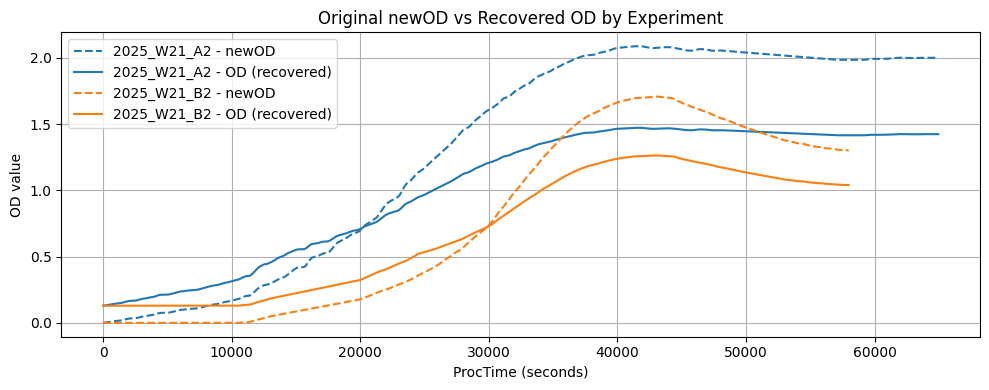

10870    71.005832
10871    71.004199
10872    71.001465
10873    70.997014
10874    70.985243
10875    70.975713
10876    70.968851
10877    70.961047
10878    70.953199
10879    70.952110
Name: pO2_adjust_scaled1, dtype: float64
0    83.039081
1    83.039917
2    83.041116
3    83.042829
4    83.043949
5    83.044373
6    83.044321
7    83.042991
8    83.041989
9    83.041175
Name: pO2_adjust_scaled1, dtype: float64
(19844, 15)
    ProcTime        OD  Substrate  Weight_In  Weight_Out  Weight_In2  \
0        0.0  0.029046   8.475828        0.0         0.0         NaN   
5       60.0  0.029693   8.469082        0.0         0.0         NaN   
10     120.0  0.030341   8.462337        0.0         0.0         NaN   
15     180.0  0.030988   8.455591        0.0         0.0         NaN   
20     240.0  0.031636   8.448846        0.0         0.0         NaN   

   experiment_id  ExitCO2_adjust_scaled1  pO2_adjust_scaled1  pO2_adjust_fit  \
0    2025_W12_A2                    0.04           83

In [ ]:
## Full data
do_mean = standard_scaler.mean_[2]
do_std = standard_scaler.scale_[2]

data_stack_full = pd.read_csv(os.path.join(datapath, "stacked_experiment_data_w_phasecluster.csv"))
data_stack_full['experiment_id'] = data_stack_full['year'].astype(str) + '_W' + data_stack_full['week'].astype(str).str.zfill(2) + '_' + data_stack_full['reactor']
##'ProcTime_aligned', 'OD_aligned',
    #    'Weight_In_change', 'Weight_In2_change', 'feeding_event', 'OD_for_rate',
    #    'OD_change', 'Time_change', 'OD_change_rate', 'OD_change_rate_smooth',
    #    'OD_change_rate_scaled', 'OD_change_rate_smooth_scaled', 'merge_index',
data_stack_full = data_stack_full[['ProcTime', 'AirFlow', 'ExitCO2',
       'ExitO2', 'OD', 'pO2', 'Stirrer', 'Weight_In', 'Weight_Out',
       'Pump_Val_Acid', 'Pump_Val_Base', 'pH', 'ExitCO2_adjust', 'pO2_adjust',
       'pH_scale', 'Pump_Val_Acid_adj', 'Pump_Val_Base_adj',
       'Pump_Val_Acid_diff_bin', 'Pump_Val_Base_diff_bin', 'Substrate',
       'Timestamp', 'Substrate_AEKF', 'Substrate_EKF', 'year', 'week',
       'reactor', 'Sin', 'CO2_adjust', 'pO2_adjust_ratio', 'ExitCO2_smoother',
       'pO2_smoother', 'Weight_In2', 'experiment_id', 'OD_change_rate_smooth','cluster']]

data_stack_full['pO2_adjust_fit'] = 80.543 + 0.0030234 * data_stack_full['Stirrer'] + 2.1573 * data_stack_full['AirFlow']
data_stack_full['pO2_adjust_fit'] = data_stack_full['pO2_adjust_fit'].rolling(window=50, center=True, min_periods=1).mean()
data_stack_full.loc[data_stack_full['experiment_id'] == '2024_W51_B2', 'Substrate'] = data_stack_full.loc[data_stack_full['experiment_id'] == '2024_W51_B2', 'Substrate_AEKF']

target_ids = ['2025_W21_A2', '2025_W21_B2']
mask = data_stack_full['experiment_id'].isin(target_ids)
data_stack_full['newOD']  = np.nan
data_stack_full.loc[mask, 'newOD'] = data_stack_full.loc[mask, 'OD']
data_stack_full['CDW']  = np.nan
a, b = 12.196, 2.1023
data_stack_full.loc[mask, 'CDW'] = a * data_stack_full.loc[mask, 'newOD'] + b

def invert_cdw_to_old_od(cdw_vals):
    cdw_vals = np.array(cdw_vals)
    OD_vals = np.zeros_like(cdw_vals)

    # Invert upper segment: CDW = 22.187 * OD - 5.0991 → OD = (CDW + 5.0991) / 22.187
    high_mask = cdw_vals >= (22.187 * 0.5207 - 5.0991)
    OD_vals[high_mask] = (cdw_vals[high_mask] + 5.0991) / 22.187

    # Invert lower segment: CDW = 11.124 * OD + 0.66116 → OD = (CDW - 0.66116) / 11.124
    low_mask = ~high_mask
    OD_vals[low_mask] = (cdw_vals[low_mask] - 0.66116) / 11.124

    return OD_vals

cdw_values = data_stack_full.loc[mask, 'CDW']
data_stack_full.loc[mask, 'OD'] = invert_cdw_to_old_od(cdw_values)

exp_ids = ['2025_W21_A2', '2025_W21_B2']
colors = ['tab:blue', 'tab:orange']

plt.figure(figsize=(10, 4))

for exp_id, color in zip(exp_ids, colors):
    df_exp = data_stack_full[data_stack_full['experiment_id'] == exp_id]
    
    # Plot newOD (original)
    plt.plot(df_exp['ProcTime'], df_exp['newOD'], label=f'{exp_id} - newOD', linestyle='--', color=color)
    
    # Plot recovered OD
    plt.plot(df_exp['ProcTime'], df_exp['OD'], label=f'{exp_id} - OD (recovered)', linestyle='-', color=color)

# Labels and formatting
plt.xlabel('ProcTime (seconds)')
plt.ylabel('OD value')
plt.title('Original newOD vs Recovered OD by Experiment')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

def scale_within_group(series, new_min=0.04, new_max=1.0):
    min_val = series.min()
    max_val = series.max()
    if min_val == max_val:
        return pd.Series([new_min] * len(series), index=series.index)  # Handle constant values
    scaled = (series - min_val) / (max_val - min_val)
    return scaled * (new_max - new_min) + new_min

# Apply scaling group-wise
data_stack_full['ExitCO2_adjust_scaled1'] = (
    data_stack_full.groupby('experiment_id')['ExitCO2_adjust']
    .transform(lambda x: scale_within_group(x, 0.04, 1))
)

target_exp = '2025_W10_B2'
target_min = data_stack_full.loc[data_stack_full['experiment_id'] == target_exp, 'pO2_adjust'].min()
target_max = data_stack_full.loc[data_stack_full['experiment_id'] == target_exp, 'pO2_adjust'].max()

def scale_to_target_range(series, tmin, tmax):
    src_min, src_max = series.min(), series.max()
    if src_min == src_max:
        return pd.Series(tmin, index=series.index)
    scaled = (series - src_min) / (src_max - src_min)
    return scaled * (tmax - tmin) + tmin

# 1) Copy original values as default
data_stack_full['pO2_adjust_scaled1'] = data_stack_full['pO2_adjust']

# 2) Compute scaled only for the target experiment
mask = data_stack_full['experiment_id'] == target_exp
scaled = scale_to_target_range(
    data_stack_full.loc[mask, 'pO2_adjust'],
    target_min,
    target_max
)

# 3) Assign back
data_stack_full.loc[mask, 'pO2_adjust_scaled1'] = scaled
print(data_stack_full.loc[mask, 'pO2_adjust_scaled1'].head(10))
print(data_stack_full.loc[~mask, 'pO2_adjust_scaled1'].head(10))

OD_vals = data_stack_full['OD'].values
CDWcu = np.where(
    OD_vals >= 0.5207,
    22.187 * OD_vals - 5.0991,
    11.124 * OD_vals + 0.66116
)
data_stack_full['CDWcu'] = CDWcu

data_for_scale_st_full = data_stack_full.loc[data_stack_full['ProcTime'] % t_freq == 0 , ['ProcTime', 'OD', 'Substrate', 'Weight_In', 'Weight_Out', 'Weight_In2', 'experiment_id',
       'ExitCO2_adjust_scaled1', 'pO2_adjust_scaled1', 'pO2_adjust_fit', 'Sin', 'CDWcu', 'Stirrer', 'AirFlow']].copy()
data_for_scale_st_full['pO2_fit_diff'] = data_for_scale_st_full['pO2_adjust_fit'] - data_for_scale_st_full['pO2_adjust_scaled1']
print(data_for_scale_st_full.shape)
print(data_for_scale_st_full.head(5))
df_pred = data_for_scale_st_full.copy()
df_pred = df_pred.sort_values(['experiment_id', 'ProcTime'])

for col in feature_prevs:
    df_pred[f'{col}_prev'] = df_pred.groupby('experiment_id')[col].shift(1)

def safe_divide(numerator, denominator):
    return np.where((denominator == 0) | (denominator.isna()), np.nan, numerator / denominator)

df_pred['pO2_change'] = safe_divide(df_pred['pO2_adjust_scaled1'], df_pred['pO2_adjust_scaled1_prev'])
df_pred['OD_change'] = safe_divide(df_pred['OD'] - df_pred['OD_prev'], df_pred['OD_prev'])
df_pred['Substrate_change'] = safe_divide(df_pred['Substrate'] - df_pred['Substrate_prev'], df_pred['OD_prev'])

df_pred['Feed'] = (np.abs(df_pred['Weight_In'] - df_pred['Weight_In_prev']) > 0)

# Step 3: Drop rows with NaNs from shift or missing values
df_pred_model = df_pred.dropna(subset=feature_cols)
X_pred = df_pred_model[feature_cols]
print(X_pred.shape)
df_pred_model['cluster_pred'] = rf.predict(X_pred)


# Step 5: Merge predicted clusters back to original `data_for_scale_st`
data_for_scale_st_full = data_for_scale_st_full.merge(
    df_pred_model[['experiment_id', 'ProcTime', 'cluster_pred']],
    on=['experiment_id', 'ProcTime'],
    how='left'
)

missing_count = data_for_scale_st_full['cluster_pred'].isna().sum()
print(f"Missing values in cluster_pred: {missing_count}")
data_for_scale_st_full['cluster_pred'] = data_for_scale_st_full['cluster_pred'].fillna(1)

data_for_scale_st_full['cluster_pred_mapped'] = data_for_scale_st_full['cluster_pred'].map(mapping)

data_for_scale_st_full = data_for_scale_st_full.sort_values(['experiment_id', 'ProcTime'])
weight_cols = ['Weight_In', 'Weight_Out', 'Weight_In2']

for col in weight_cols:
    data_for_scale_st_full[f'{col}_diff'] = data_for_scale_st_full.groupby('experiment_id')[col].diff().abs().fillna(0)
print(data_for_scale_st_full.columns)
print(data_for_scale_st_full.head(5))

################################################# Add column of V, OD after dilute/feed, S change after feed in/out
data_for_scale_st_full = data_for_scale_st_full.sort_values(['experiment_id', 'ProcTime'])

OD_vals = data_for_scale_st_full['OD'].values
CDWcu = np.where(
    OD_vals >= 0.5207,
    22.187 * OD_vals - 5.0991,
    11.124 * OD_vals + 0.66116
)
data_for_scale_st_full['CDWcu'] = CDWcu

# Initialize columns
data_for_scale_st_full['V'] = np.nan
data_for_scale_st_full['OD_mod'] = np.nan
data_for_scale_st_full['S_mod'] = np.nan
data_for_scale_st_full['S_consume'] = np.nan
data_for_scale_st_full['OD_growth'] = np.nan
data_for_scale_st_full['mu_max_cal'] = np.nan

# Calculate for each experiment_id
for exp_id, df_exp in data_for_scale_st_full.groupby('experiment_id'):
    df_exp = df_exp.copy()
    V_list = [1]  # Initial volume
    row = df_exp.iloc[0] 
    OD_mod_0 = row['OD'] * V_list[0] / (V_list[0] + (row['Weight_In_diff'] + row['Weight_In2_diff']) / 1000)
    OD_mod_list = [OD_mod_0]
    S_mod_0 = (row['Substrate'] * V_list[0] + row['Sin'] * row['Weight_In_diff'] / 1000) / (V_list[0] + row['Weight_In_diff'] / 1000 + row['Weight_In2_diff'] / 1000)
    S_mod_list = [S_mod_0]
    S_consume = [0]
    initOD = row['OD'] * V_list[0]
    OD_growth = [initOD]
    for i in range(1, len(df_exp)):
        prev_V = V_list[-1]
        prev_row = df_exp.iloc[i-1] 
        row = df_exp.iloc[i] 
        in_vol = (prev_row['Weight_In_diff'] + prev_row['Weight_In2_diff']) / 1000
        out_vol = prev_row['Weight_Out_diff'] / 1000
        new_V = prev_V + in_vol - out_vol
        V_list.append(new_V)
        new_OD = row['OD'] * new_V / (new_V + (row['Weight_In_diff'] + row['Weight_In2_diff']) / 1000)
        OD_mod_list.append(new_OD)
        new_S = (row['Substrate'] * new_V + row['Sin'] * row['Weight_In_diff'] / 1000) / (new_V + row['Weight_In_diff'] / 1000 + row['Weight_In2_diff'] / 1000)
        S_mod_list.append(new_S)
        S_consume.append(max(0, (prev_row['Substrate'] * prev_V - row['Substrate'] * new_V - prev_row['Sin'] * prev_row['Weight_In_diff'] / 1000 + (prev_row['Substrate'] + row['Substrate']) / 2 * prev_row['Weight_Out_diff'] / 1000)))
        OD_growth.append(row['OD'] * new_V - prev_row['OD'] * prev_V + (prev_row['OD'] + row['OD']) / 2 * prev_row['Weight_Out_diff'] / 1000)
        
    df_exp['V'] = V_list
    df_exp['OD_mod'] = OD_mod_list
    df_exp['S_mod'] = S_mod_list
    df_exp['S_consume'] = S_consume
    df_exp['OD_growth'] = OD_growth

    K_s = 0.007
    k_d = 0.006

    df_exp = df_exp.sort_values('ProcTime')
    df_exp['dX_dt'] = df_exp['CDWcu'].diff() / (df_exp['ProcTime'].diff()/3600)  # ∆X / ∆t

    # Compute μ_max approximately
    numerator = df_exp['dX_dt'] + ((df_exp['Weight_In_diff'] + df_exp['Weight_In2_diff']) / 1000 / (df_exp['ProcTime'].diff()/3600) / df_exp['V'] + k_d) * df_exp['CDWcu']
    denominator = (df_exp['Substrate'] / (K_s + df_exp['Substrate'])) * df_exp['CDWcu']
    df_exp['mu_max_cal'] = np.where(
        np.abs(denominator) > 1e-8,
        numerator / denominator,
        0  # fallback value when denominator is 0 or too small
    )

    # Filter out unrealistic values (optional)
    df_exp['mu_max_cal'] = df_exp['mu_max_cal'].clip(lower=0, upper=0.65) # upper 99% quantile
    ## Make weight in all positive
    min_weight_in = df_exp['Weight_In'].min()
    df_exp['Weight_In'] = df_exp['Weight_In'] - min_weight_in

    # Assign back to original
    data_for_scale_st_full.loc[df_exp.index, ['V', 'OD_mod', 'S_mod', 'S_consume', 'OD_growth', 'mu_max_cal', 'Weight_In']] = df_exp[['V', 'OD_mod', 'S_mod', 'S_consume', 'OD_growth', 'mu_max_cal', 'Weight_In']]

data_for_scale_st_full['mu_max_cal'] = data_for_scale_st_full['mu_max_cal'].bfill()
data_for_scale_st_full['Feed_ON'] = (data_for_scale_st_full['Weight_In_diff'].rolling(window=5, min_periods=1).mean() > 0.01).astype(float) * 0.1
data_for_scale_st_full['Waste_ON'] = (data_for_scale_st_full['Weight_Out_diff'].rolling(window=5, min_periods=1).mean() > 0.01).astype(float) * 0.1
data_for_scale_st_full['Dilution_ON'] = (data_for_scale_st_full['Weight_In2_diff'].rolling(window=5, min_periods=1).mean() > 0.01).astype(float) * 0.1
data_for_scale_st_full['S_feed_g'] = data_for_scale_st_full['Sin'] * data_for_scale_st_full['Weight_In_diff'] / 1000
data_for_scale_st_full['S_feed_g'] = data_for_scale_st_full['S_feed_g'].clip(lower=0)
data_for_scale_st_full['S_feed_gL'] = data_for_scale_st_full['Sin'] * data_for_scale_st_full['Weight_In_diff'] / 1000 / (data_for_scale_st_full['V'] + data_for_scale_st_full['Weight_In_diff'] / 1000 + data_for_scale_st_full['Weight_In2_diff'] / 1000)
data_for_scale_st_full['S_feed_gL'] = data_for_scale_st_full['S_feed_gL'].clip(lower=0)
data_for_scale_st_full['DilutionFactor'] = data_for_scale_st_full['V'] / (data_for_scale_st_full['V'] + data_for_scale_st_full['Weight_In_diff'] / 1000 + data_for_scale_st_full['Weight_In2_diff'] / 1000)
data_for_scale_st_full['Weight_In_Diff_tot'] = data_for_scale_st_full['Weight_In_diff'] + data_for_scale_st_full['Weight_In2_diff']


#'OD', 'Substrate',
# numerical_features = [
#     'ProcTime', 'ExitCO2_adjust_scaled1', 
#     'pO2_adjust_scaled1', 'pO2_adjust_fit',
#     'Weight_In_diff', 'Weight_Out_diff', 'Weight_In2_diff',
#     'V', 'OD_mod', 'S_mod'
# ]
# categorical_feature = 'cluster_pred'


# MinMax Scaling
numerical_scaled_minmax = minmax_scaler.transform(data_for_scale_st_full[numerical_features])
df_minmax = pd.DataFrame(numerical_scaled_minmax, columns=numerical_features, index=data_for_scale_st_full.index)

data_for_scale_st_full['OD_mmscaled'] = (data_for_scale_st_full['OD'] - od_min) / (od_max - od_min)
data_for_scale_st_full['Substrate_mmscaled'] = (data_for_scale_st_full['Substrate'] - s_min) / (s_max - s_min)

# Standard Scaling
numerical_scaled_standard = standard_scaler.transform(data_for_scale_st_full[numerical_features])
df_standard = pd.DataFrame(numerical_scaled_standard, columns=numerical_features, index=data_for_scale_st_full.index)

data_for_scale_st_full['OD_stscaled'] = (data_for_scale_st_full['OD'] - od_mean) / od_std

data_for_scale_st_full['Substrate_stscaled'] = (data_for_scale_st_full['Substrate'] - s_mean) / s_std

# cluster_encoded = onehot.transform(data_for_scale_st_full[[categorical_feature]])
# cluster_columns = [f"{categorical_feature}_{int(cat)}" for cat in onehot.categories_[0]]
# df_cluster = pd.DataFrame(cluster_encoded, columns=cluster_columns, index=data_for_scale_st_full.index)

df_combined_minmax_full = pd.concat([df_minmax, data_for_scale_st_full[categorical_feature]], axis=1)
df_combined_standard_full = pd.concat([df_standard, data_for_scale_st_full[categorical_feature]], axis=1)

print(df_combined_minmax_full.head(5))
print(df_combined_standard_full.head(5))


6
-----------------------------------------------------------------

=== Training model 1/100 ===


C:\Users\yiwenl\AppData\Local\Temp\ipykernel_24268\1416190750.py:64: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\utils\tensor_new.cpp:281.)
  x_tensor = torch.tensor(x_sub, dtype=torch.float32)


Epoch [20/120], Train Loss: 0.0393, Test Loss: 0.0452, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0147, Test Loss: 0.0213, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0108, Test Loss: 0.0157, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0101, Test Loss: 0.0147, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0092, Test Loss: 0.0134, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0088, Test Loss: 0.0127, Current LR: 0.00250


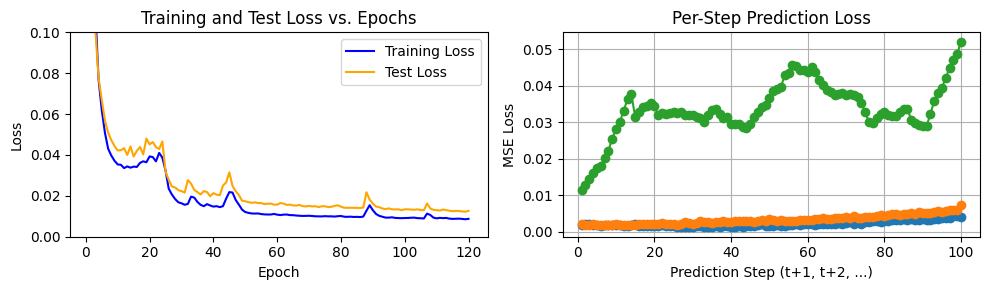

-----------------------------------------------------------------

=== Training model 2/100 ===
Epoch [20/120], Train Loss: 0.0414, Test Loss: 0.0497, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0172, Test Loss: 0.0190, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0110, Test Loss: 0.0139, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0098, Test Loss: 0.0125, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0091, Test Loss: 0.0117, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0086, Test Loss: 0.0107, Current LR: 0.00250


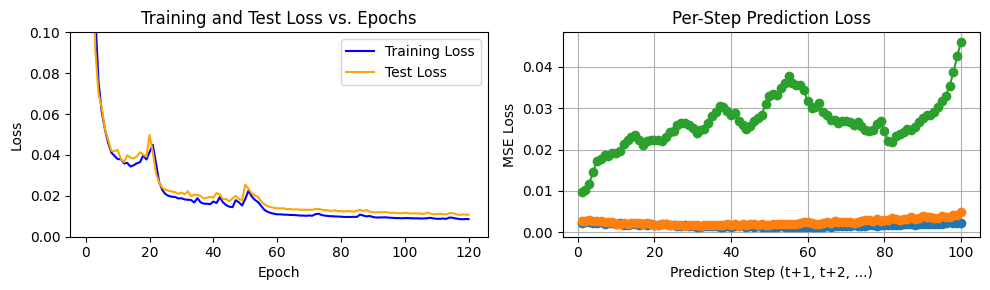

-----------------------------------------------------------------

=== Training model 3/100 ===
Epoch [20/120], Train Loss: 0.0337, Test Loss: 0.0383, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0141, Test Loss: 0.0190, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0135, Test Loss: 0.0166, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0093, Test Loss: 0.0134, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0088, Test Loss: 0.0122, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0081, Test Loss: 0.0114, Current LR: 0.00250


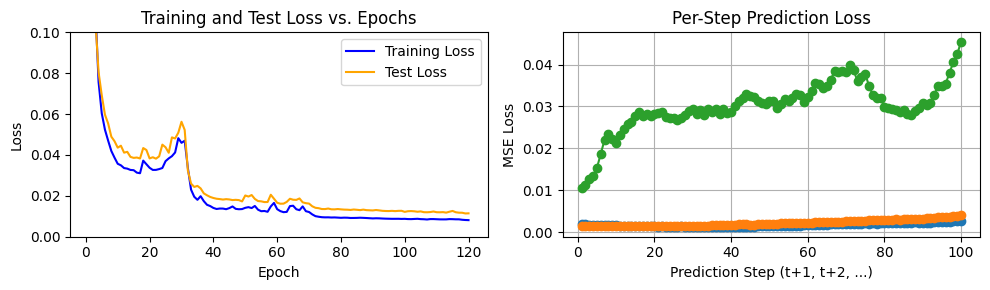

-----------------------------------------------------------------

=== Training model 4/100 ===
Epoch [20/120], Train Loss: 0.0419, Test Loss: 0.0408, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0136, Test Loss: 0.0173, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0126, Test Loss: 0.0159, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0097, Test Loss: 0.0139, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0086, Test Loss: 0.0123, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0078, Test Loss: 0.0107, Current LR: 0.00250


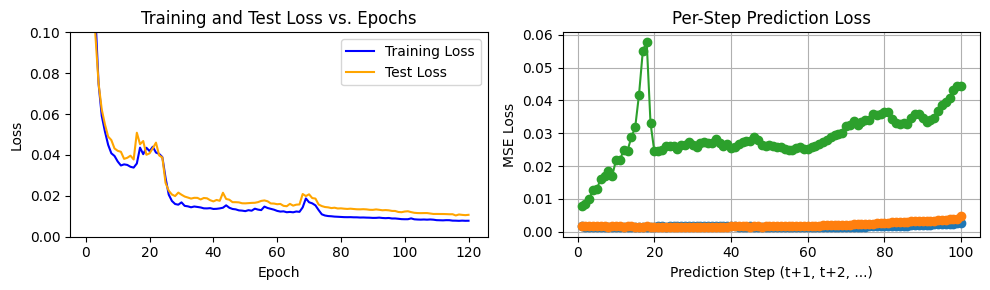

-----------------------------------------------------------------

=== Training model 5/100 ===
Epoch [20/120], Train Loss: 0.0366, Test Loss: 0.0377, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0134, Test Loss: 0.0182, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0099, Test Loss: 0.0145, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0094, Test Loss: 0.0133, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0092, Test Loss: 0.0131, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0085, Test Loss: 0.0119, Current LR: 0.00250


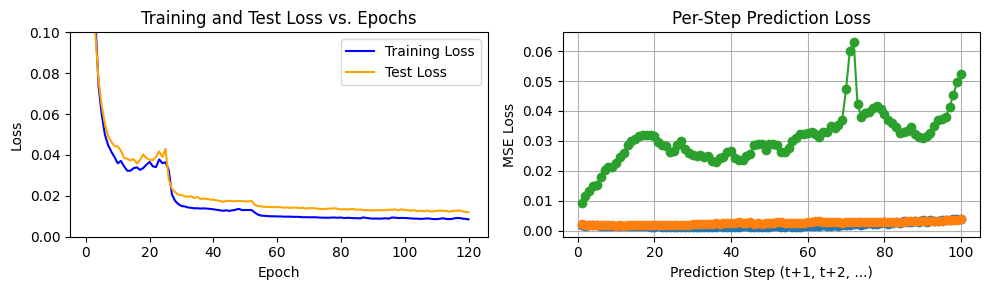

-----------------------------------------------------------------

=== Training model 6/100 ===
Epoch [20/120], Train Loss: 0.0360, Test Loss: 0.0414, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0139, Test Loss: 0.0190, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0107, Test Loss: 0.0149, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0094, Test Loss: 0.0134, Current LR: 0.00125
Epoch [100/120], Train Loss: 0.0084, Test Loss: 0.0123, Current LR: 0.00125
Epoch [120/120], Train Loss: 0.0080, Test Loss: 0.0116, Current LR: 0.00125


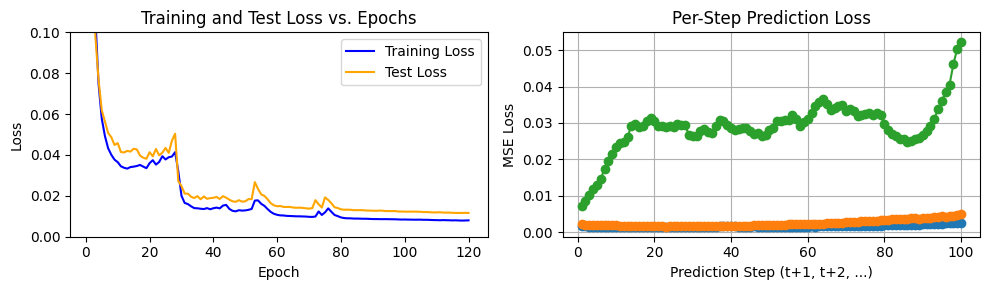

-----------------------------------------------------------------

=== Training model 7/100 ===
Epoch [20/120], Train Loss: 0.0342, Test Loss: 0.0391, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0147, Test Loss: 0.0209, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0138, Test Loss: 0.0192, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0093, Test Loss: 0.0142, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0086, Test Loss: 0.0134, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0085, Test Loss: 0.0130, Current LR: 0.00250


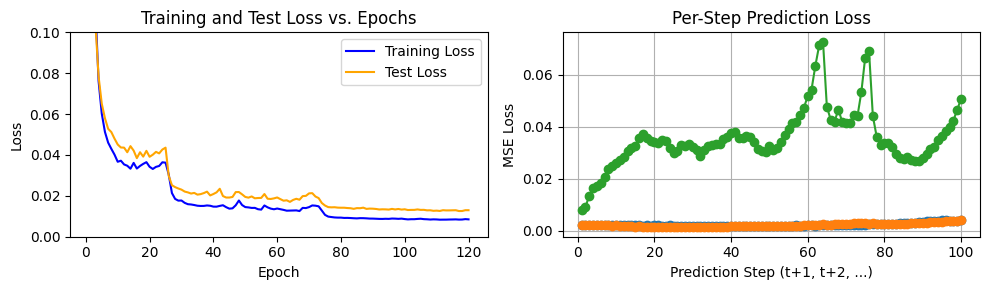

-----------------------------------------------------------------

=== Training model 8/100 ===
Epoch [20/120], Train Loss: 0.0449, Test Loss: 0.0481, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0139, Test Loss: 0.0170, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0136, Test Loss: 0.0160, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0097, Test Loss: 0.0121, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0089, Test Loss: 0.0111, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0084, Test Loss: 0.0106, Current LR: 0.00250


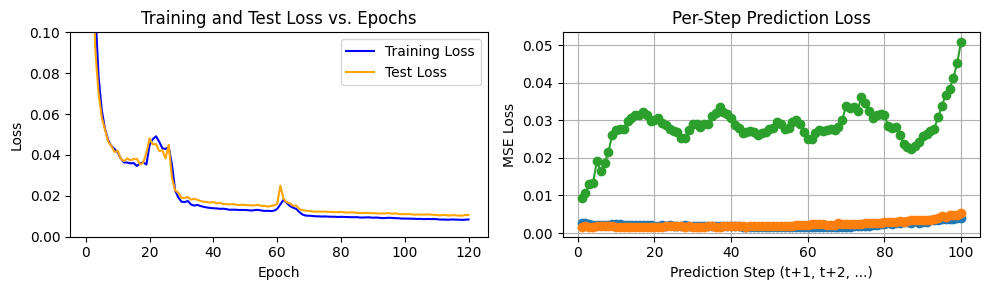

-----------------------------------------------------------------

=== Training model 9/100 ===
Epoch [20/120], Train Loss: 0.0364, Test Loss: 0.0367, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0139, Test Loss: 0.0182, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0106, Test Loss: 0.0142, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0091, Test Loss: 0.0128, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0085, Test Loss: 0.0121, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0078, Test Loss: 0.0111, Current LR: 0.00250


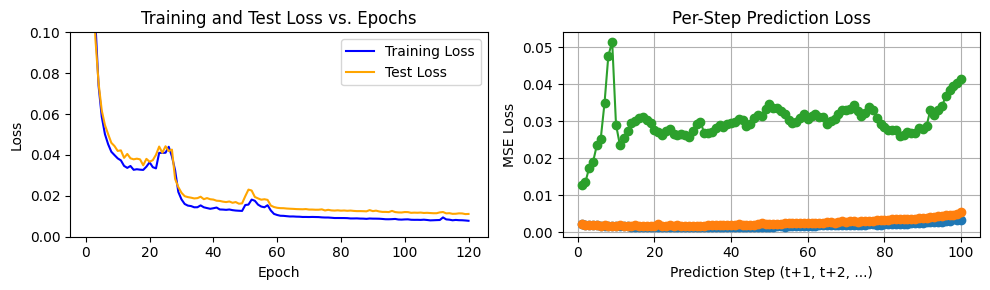

-----------------------------------------------------------------

=== Training model 10/100 ===
Epoch [20/120], Train Loss: 0.0320, Test Loss: 0.0380, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0140, Test Loss: 0.0199, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0125, Test Loss: 0.0178, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0094, Test Loss: 0.0142, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0088, Test Loss: 0.0129, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0082, Test Loss: 0.0119, Current LR: 0.00250


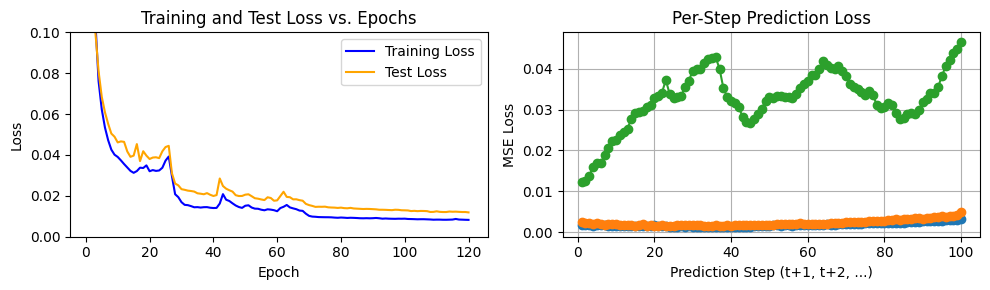

-----------------------------------------------------------------

=== Training model 11/100 ===
Epoch [20/120], Train Loss: 0.0323, Test Loss: 0.0423, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0172, Test Loss: 0.0219, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0112, Test Loss: 0.0162, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0098, Test Loss: 0.0143, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0090, Test Loss: 0.0135, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0086, Test Loss: 0.0125, Current LR: 0.00250


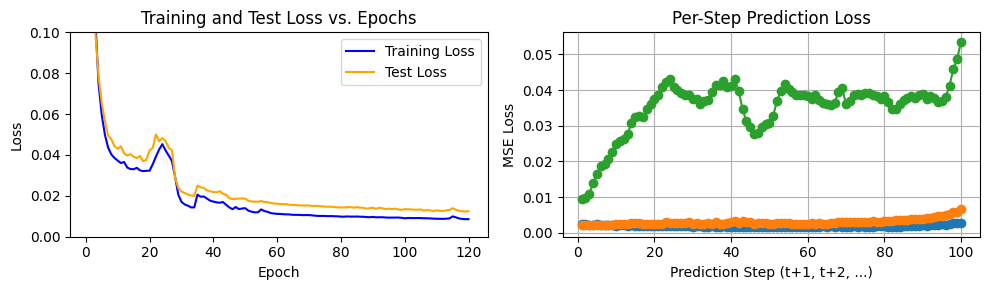

-----------------------------------------------------------------

=== Training model 12/100 ===
Epoch [20/120], Train Loss: 0.0333, Test Loss: 0.0416, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0140, Test Loss: 0.0186, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0151, Test Loss: 0.0183, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0094, Test Loss: 0.0132, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0090, Test Loss: 0.0127, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0085, Test Loss: 0.0122, Current LR: 0.00250


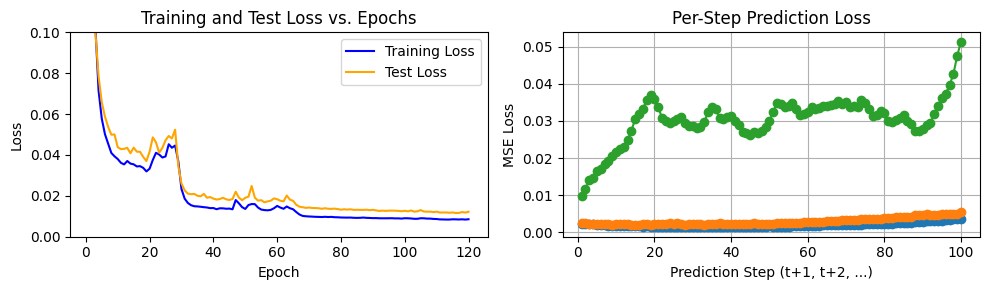

-----------------------------------------------------------------

=== Training model 13/100 ===
Epoch [20/120], Train Loss: 0.0338, Test Loss: 0.0452, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0145, Test Loss: 0.0193, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0126, Test Loss: 0.0165, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0089, Test Loss: 0.0124, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0083, Test Loss: 0.0113, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0072, Test Loss: 0.0103, Current LR: 0.00125


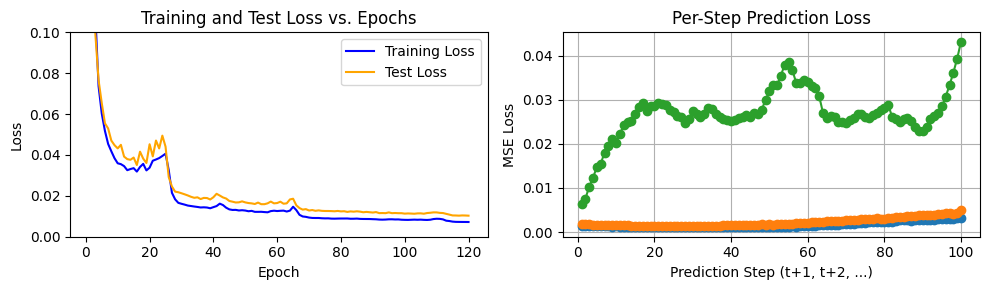

-----------------------------------------------------------------

=== Training model 14/100 ===
Epoch [20/120], Train Loss: 0.0315, Test Loss: 0.0367, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0133, Test Loss: 0.0189, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0101, Test Loss: 0.0153, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0091, Test Loss: 0.0141, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0082, Test Loss: 0.0127, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0075, Test Loss: 0.0118, Current LR: 0.00250


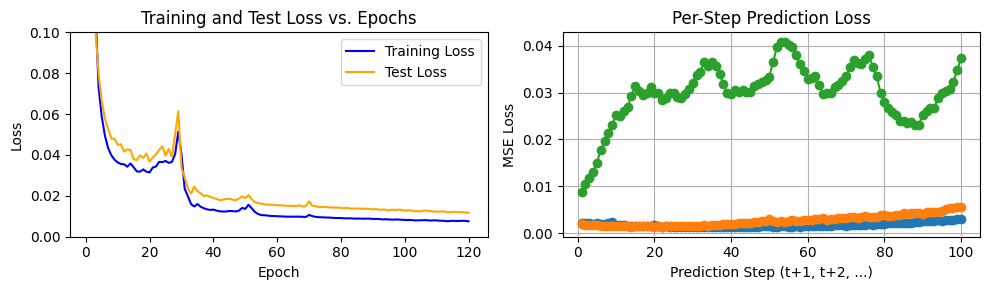

-----------------------------------------------------------------

=== Training model 15/100 ===
Epoch [20/120], Train Loss: 0.0336, Test Loss: 0.0355, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0176, Test Loss: 0.0199, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0126, Test Loss: 0.0157, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0088, Test Loss: 0.0121, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0086, Test Loss: 0.0111, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0081, Test Loss: 0.0104, Current LR: 0.00250


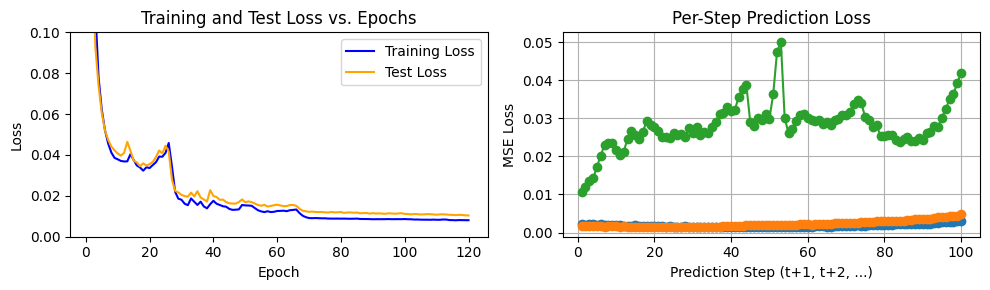

-----------------------------------------------------------------

=== Training model 16/100 ===
Epoch [20/120], Train Loss: 0.0397, Test Loss: 0.0556, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0153, Test Loss: 0.0205, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0128, Test Loss: 0.0186, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0099, Test Loss: 0.0147, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0088, Test Loss: 0.0131, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0081, Test Loss: 0.0125, Current LR: 0.00125


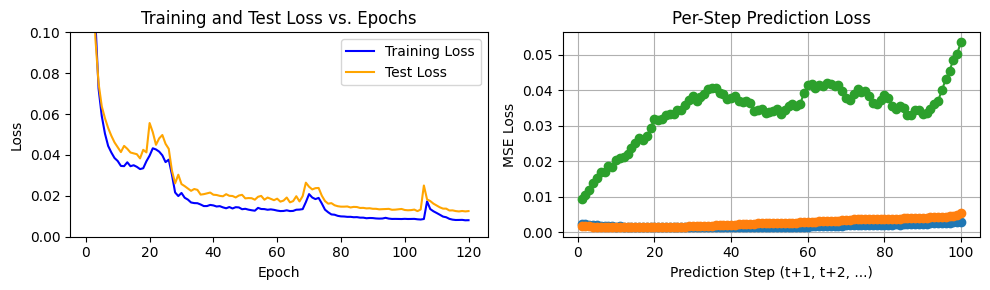

-----------------------------------------------------------------

=== Training model 17/100 ===
Epoch [20/120], Train Loss: 0.0351, Test Loss: 0.0428, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0175, Test Loss: 0.0221, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0177, Test Loss: 0.0229, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0102, Test Loss: 0.0148, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0096, Test Loss: 0.0139, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0080, Test Loss: 0.0120, Current LR: 0.00125


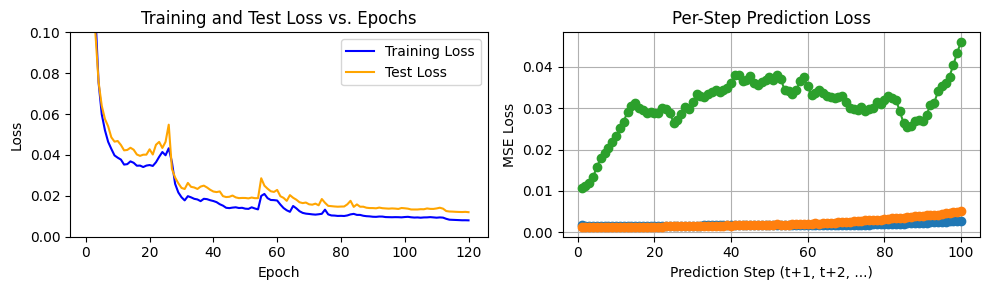

-----------------------------------------------------------------

=== Training model 18/100 ===
Epoch [20/120], Train Loss: 0.0385, Test Loss: 0.0454, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0142, Test Loss: 0.0184, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0123, Test Loss: 0.0159, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0083, Test Loss: 0.0119, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0078, Test Loss: 0.0110, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0075, Test Loss: 0.0103, Current LR: 0.00250


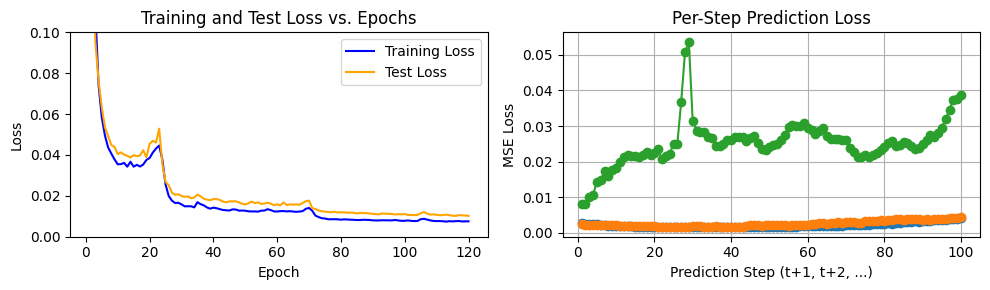

-----------------------------------------------------------------

=== Training model 19/100 ===
Epoch [20/120], Train Loss: 0.0322, Test Loss: 0.0375, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0144, Test Loss: 0.0193, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0131, Test Loss: 0.0175, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0100, Test Loss: 0.0140, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0093, Test Loss: 0.0133, Current LR: 0.00125
Epoch [120/120], Train Loss: 0.0089, Test Loss: 0.0124, Current LR: 0.00125


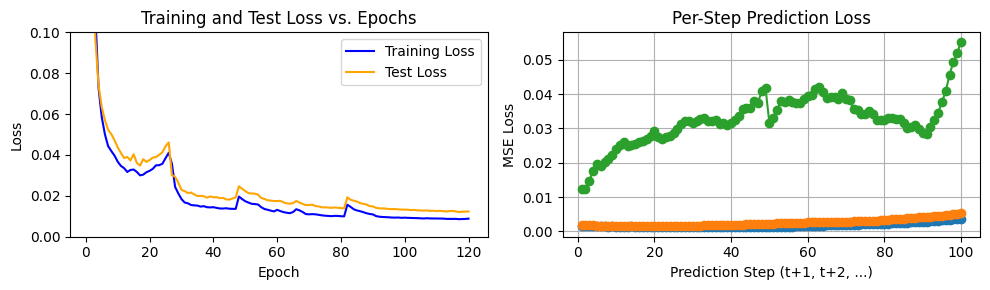

-----------------------------------------------------------------

=== Training model 20/100 ===
Epoch [20/120], Train Loss: 0.0347, Test Loss: 0.0403, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0129, Test Loss: 0.0211, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0120, Test Loss: 0.0167, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0115, Test Loss: 0.0163, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0080, Test Loss: 0.0116, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0074, Test Loss: 0.0110, Current LR: 0.00250


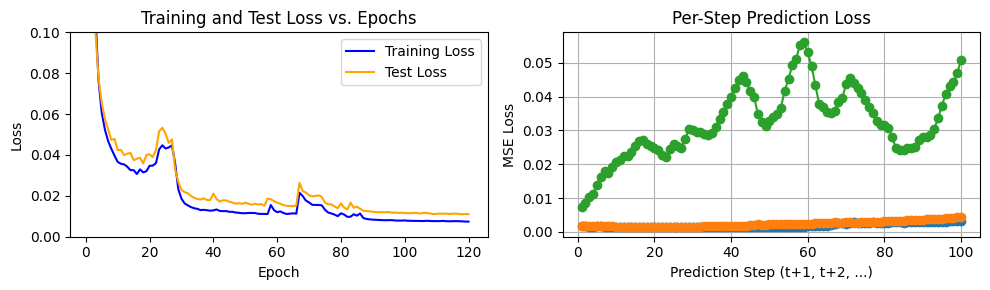

-----------------------------------------------------------------

=== Training model 21/100 ===
Epoch [20/120], Train Loss: 0.0319, Test Loss: 0.0356, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0147, Test Loss: 0.0185, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0120, Test Loss: 0.0161, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0083, Test Loss: 0.0122, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0078, Test Loss: 0.0115, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0077, Test Loss: 0.0110, Current LR: 0.00250


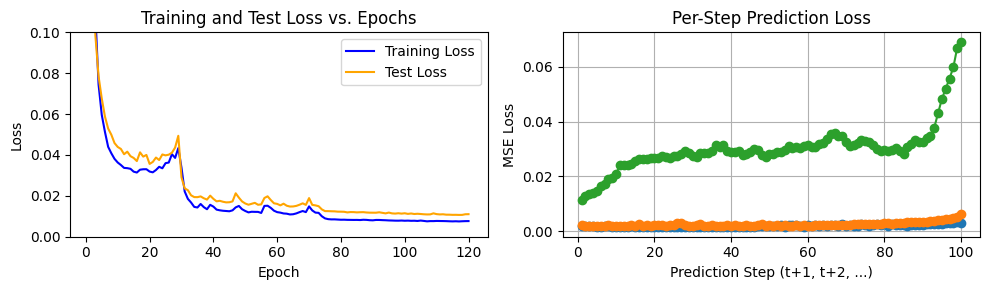

-----------------------------------------------------------------

=== Training model 22/100 ===
Epoch [20/120], Train Loss: 0.0329, Test Loss: 0.0360, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0132, Test Loss: 0.0174, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0123, Test Loss: 0.0160, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0137, Test Loss: 0.0161, Current LR: 0.00500
Epoch [100/120], Train Loss: 0.0075, Test Loss: 0.0105, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0082, Test Loss: 0.0108, Current LR: 0.00125


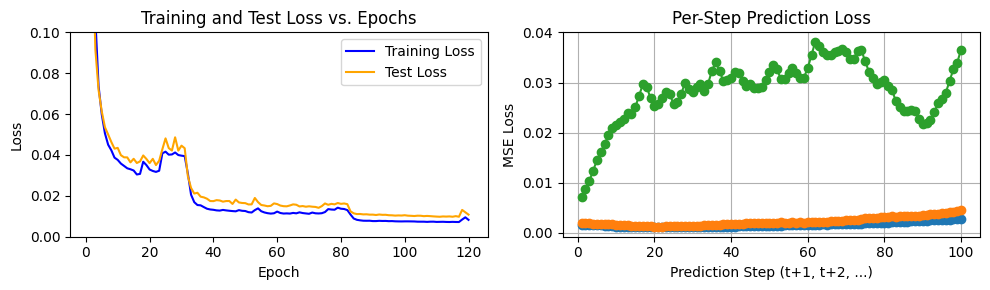

-----------------------------------------------------------------

=== Training model 23/100 ===
Epoch [20/120], Train Loss: 0.0327, Test Loss: 0.0399, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0135, Test Loss: 0.0173, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0132, Test Loss: 0.0163, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0097, Test Loss: 0.0126, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0086, Test Loss: 0.0114, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0085, Test Loss: 0.0109, Current LR: 0.00250


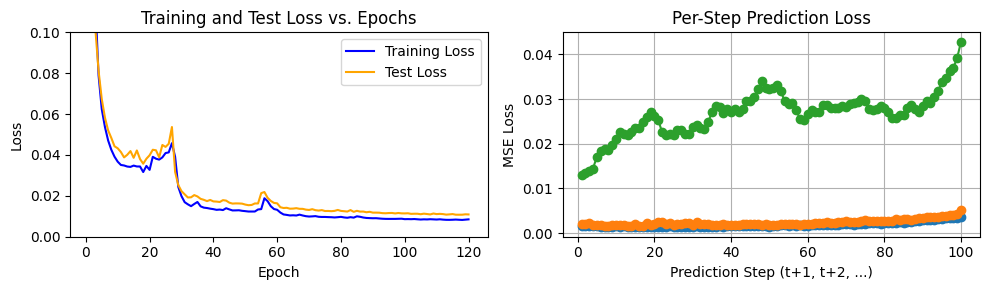

-----------------------------------------------------------------

=== Training model 24/100 ===
Epoch [20/120], Train Loss: 0.0360, Test Loss: 0.0468, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0142, Test Loss: 0.0196, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0123, Test Loss: 0.0183, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0089, Test Loss: 0.0131, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0085, Test Loss: 0.0126, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0080, Test Loss: 0.0113, Current LR: 0.00250


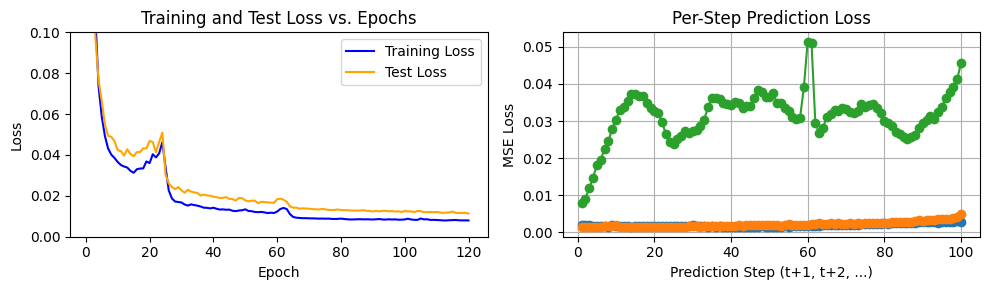

-----------------------------------------------------------------

=== Training model 25/100 ===
Epoch [20/120], Train Loss: 0.0330, Test Loss: 0.0363, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0129, Test Loss: 0.0168, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0118, Test Loss: 0.0152, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0086, Test Loss: 0.0118, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0081, Test Loss: 0.0109, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0077, Test Loss: 0.0106, Current LR: 0.00250


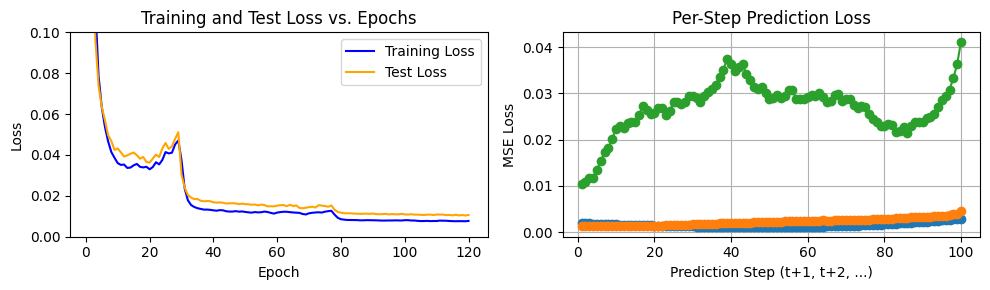

-----------------------------------------------------------------

=== Training model 26/100 ===
Epoch [20/120], Train Loss: 0.0341, Test Loss: 0.0384, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0144, Test Loss: 0.0193, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0113, Test Loss: 0.0159, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0105, Test Loss: 0.0147, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0093, Test Loss: 0.0137, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0093, Test Loss: 0.0128, Current LR: 0.00250


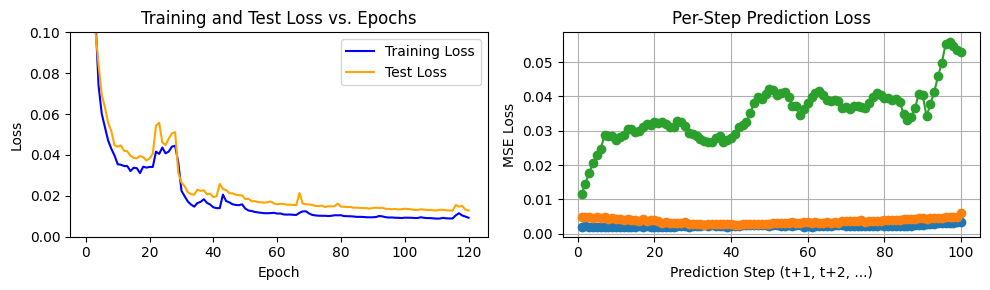

-----------------------------------------------------------------

=== Training model 27/100 ===
Epoch [20/120], Train Loss: 0.0334, Test Loss: 0.0378, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0139, Test Loss: 0.0187, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0130, Test Loss: 0.0160, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0116, Test Loss: 0.0135, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0081, Test Loss: 0.0115, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0079, Test Loss: 0.0110, Current LR: 0.00250


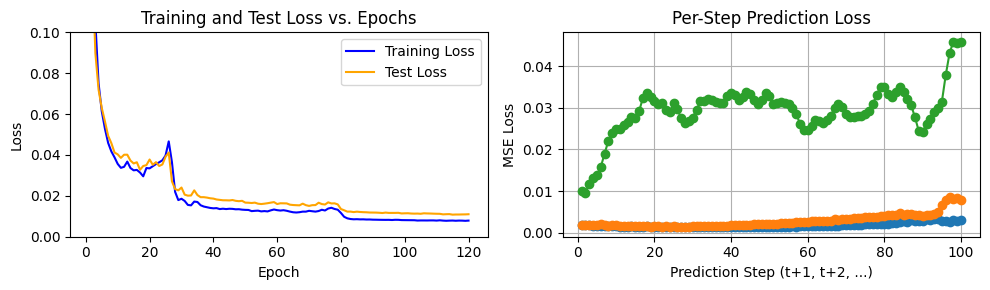

-----------------------------------------------------------------

=== Training model 28/100 ===
Epoch [20/120], Train Loss: 0.0338, Test Loss: 0.0400, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0149, Test Loss: 0.0187, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0129, Test Loss: 0.0166, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0129, Test Loss: 0.0159, Current LR: 0.00500
Epoch [100/120], Train Loss: 0.0082, Test Loss: 0.0113, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0078, Test Loss: 0.0109, Current LR: 0.00250


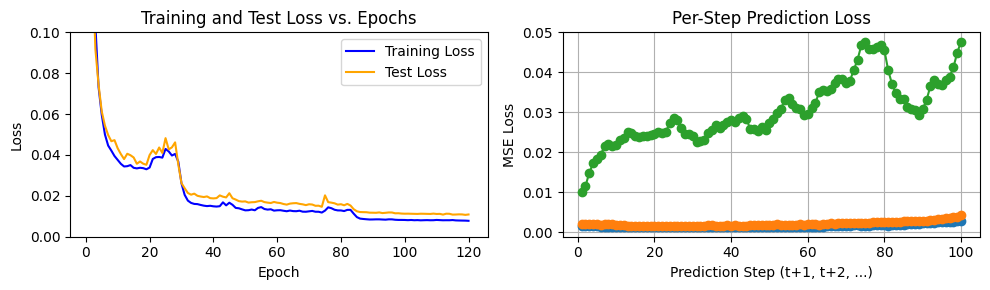

-----------------------------------------------------------------

=== Training model 29/100 ===
Epoch [20/120], Train Loss: 0.0335, Test Loss: 0.0424, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0132, Test Loss: 0.0192, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0127, Test Loss: 0.0179, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0119, Test Loss: 0.0164, Current LR: 0.00500
Epoch [100/120], Train Loss: 0.0080, Test Loss: 0.0125, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0078, Test Loss: 0.0124, Current LR: 0.00250


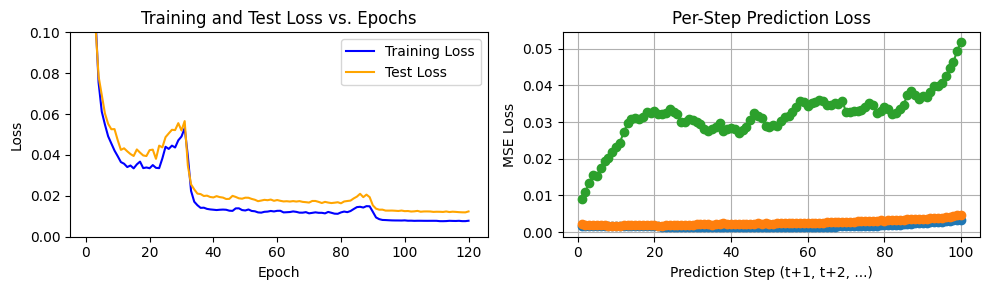

-----------------------------------------------------------------

=== Training model 30/100 ===
Epoch [20/120], Train Loss: 0.0322, Test Loss: 0.0361, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0128, Test Loss: 0.0174, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0123, Test Loss: 0.0167, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0096, Test Loss: 0.0132, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0084, Test Loss: 0.0118, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0080, Test Loss: 0.0108, Current LR: 0.00250


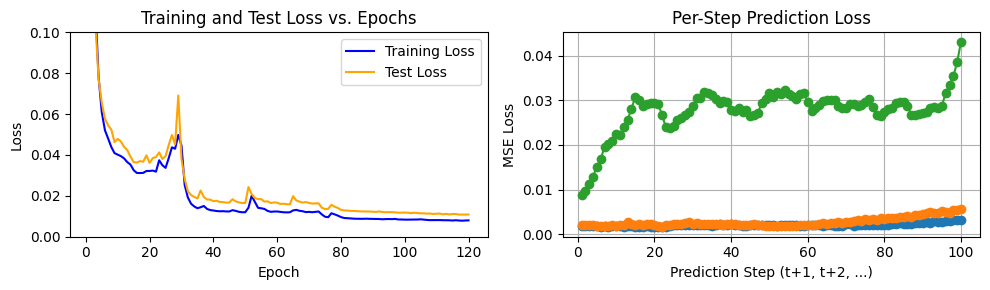

-----------------------------------------------------------------

=== Training model 31/100 ===
Epoch [20/120], Train Loss: 0.0345, Test Loss: 0.0384, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0154, Test Loss: 0.0176, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0105, Test Loss: 0.0136, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0095, Test Loss: 0.0122, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0084, Test Loss: 0.0109, Current LR: 0.00125
Epoch [120/120], Train Loss: 0.0076, Test Loss: 0.0102, Current LR: 0.00125


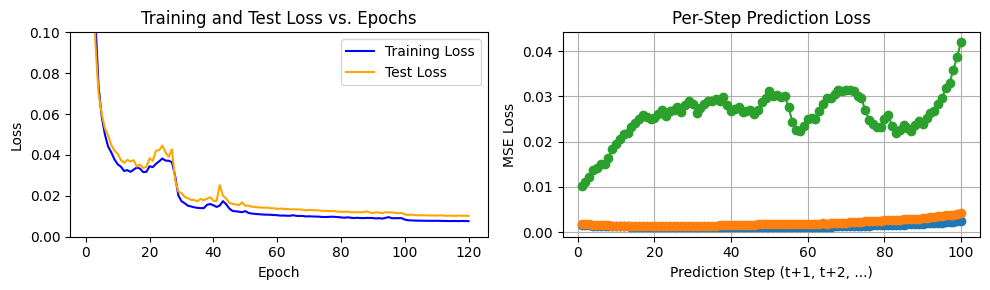

-----------------------------------------------------------------

=== Training model 32/100 ===
Epoch [20/120], Train Loss: 0.0359, Test Loss: 0.0420, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0138, Test Loss: 0.0192, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0112, Test Loss: 0.0167, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0108, Test Loss: 0.0154, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0091, Test Loss: 0.0131, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0079, Test Loss: 0.0118, Current LR: 0.00125


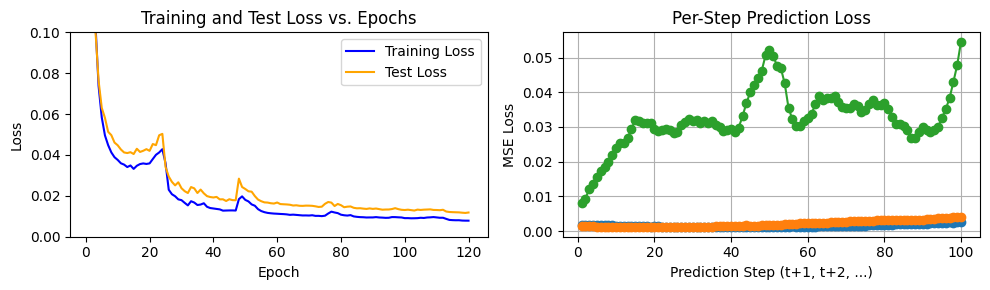

-----------------------------------------------------------------

=== Training model 33/100 ===
Epoch [20/120], Train Loss: 0.0344, Test Loss: 0.0377, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0134, Test Loss: 0.0177, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0120, Test Loss: 0.0151, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0083, Test Loss: 0.0117, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0078, Test Loss: 0.0112, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0076, Test Loss: 0.0104, Current LR: 0.00250


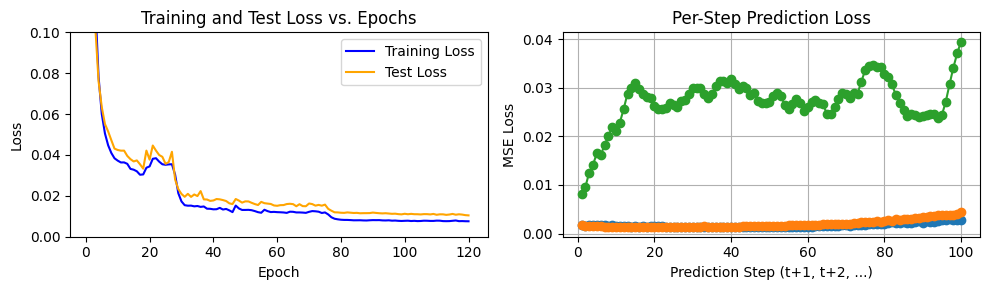

-----------------------------------------------------------------

=== Training model 34/100 ===
Epoch [20/120], Train Loss: 0.0347, Test Loss: 0.0418, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0184, Test Loss: 0.0232, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0140, Test Loss: 0.0197, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0093, Test Loss: 0.0147, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0095, Test Loss: 0.0142, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0084, Test Loss: 0.0130, Current LR: 0.00250


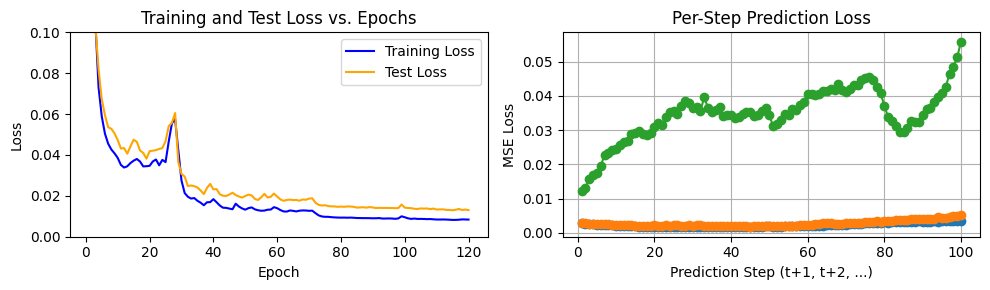

-----------------------------------------------------------------

=== Training model 35/100 ===
Epoch [20/120], Train Loss: 0.0302, Test Loss: 0.0356, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0140, Test Loss: 0.0226, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0184, Test Loss: 0.0259, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0101, Test Loss: 0.0158, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0093, Test Loss: 0.0144, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0088, Test Loss: 0.0131, Current LR: 0.00250


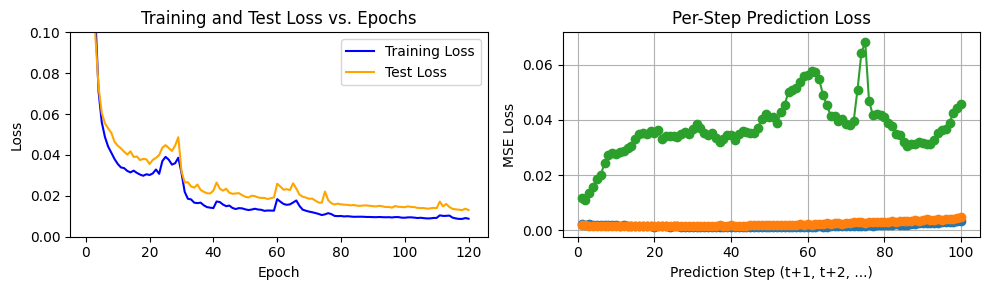

-----------------------------------------------------------------

=== Training model 36/100 ===
Epoch [20/120], Train Loss: 0.0370, Test Loss: 0.0432, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0146, Test Loss: 0.0194, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0114, Test Loss: 0.0168, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0100, Test Loss: 0.0148, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0092, Test Loss: 0.0137, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0085, Test Loss: 0.0123, Current LR: 0.00250


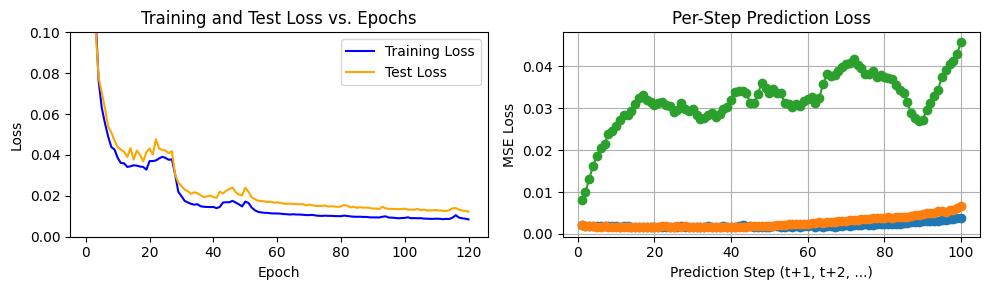

-----------------------------------------------------------------

=== Training model 37/100 ===
Epoch [20/120], Train Loss: 0.0349, Test Loss: 0.0411, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0153, Test Loss: 0.0214, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0170, Test Loss: 0.0217, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0093, Test Loss: 0.0140, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0087, Test Loss: 0.0130, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0085, Test Loss: 0.0127, Current LR: 0.00250


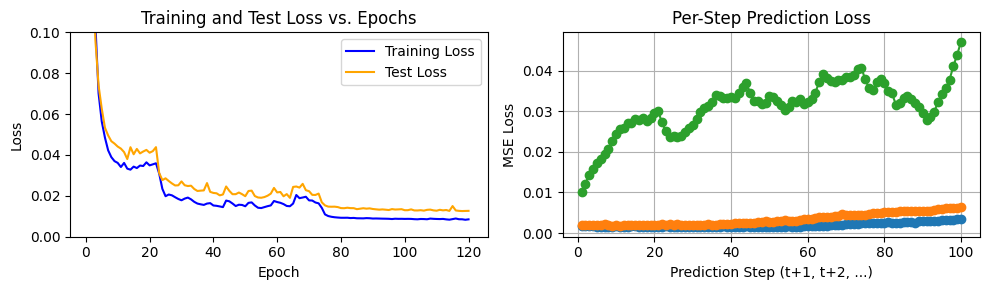

-----------------------------------------------------------------

=== Training model 38/100 ===
Epoch [20/120], Train Loss: 0.0384, Test Loss: 0.0424, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0166, Test Loss: 0.0227, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0145, Test Loss: 0.0185, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0091, Test Loss: 0.0133, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0092, Test Loss: 0.0134, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0081, Test Loss: 0.0117, Current LR: 0.00250


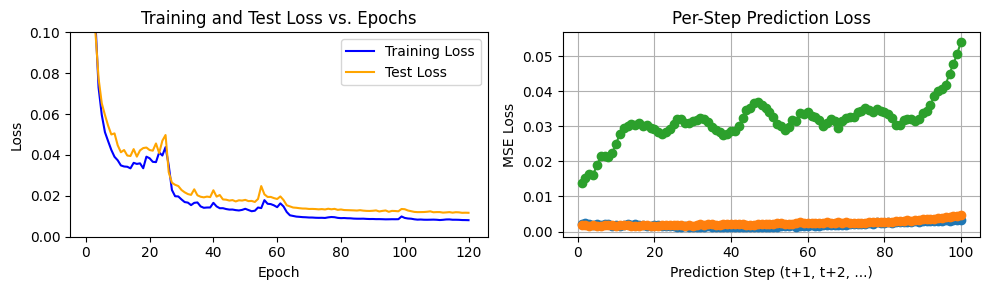

-----------------------------------------------------------------

=== Training model 39/100 ===
Epoch [20/120], Train Loss: 0.0342, Test Loss: 0.0385, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0126, Test Loss: 0.0175, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0129, Test Loss: 0.0167, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0090, Test Loss: 0.0121, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0073, Test Loss: 0.0108, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0073, Test Loss: 0.0105, Current LR: 0.00250


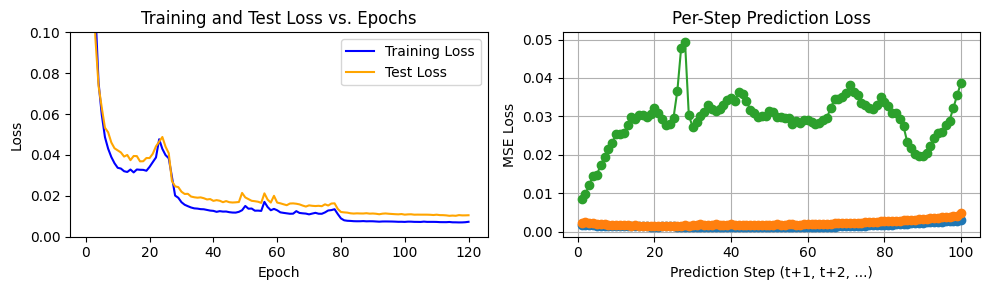

-----------------------------------------------------------------

=== Training model 40/100 ===
Epoch [20/120], Train Loss: 0.0397, Test Loss: 0.0414, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0145, Test Loss: 0.0196, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0121, Test Loss: 0.0163, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0087, Test Loss: 0.0128, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0084, Test Loss: 0.0121, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0079, Test Loss: 0.0117, Current LR: 0.00250


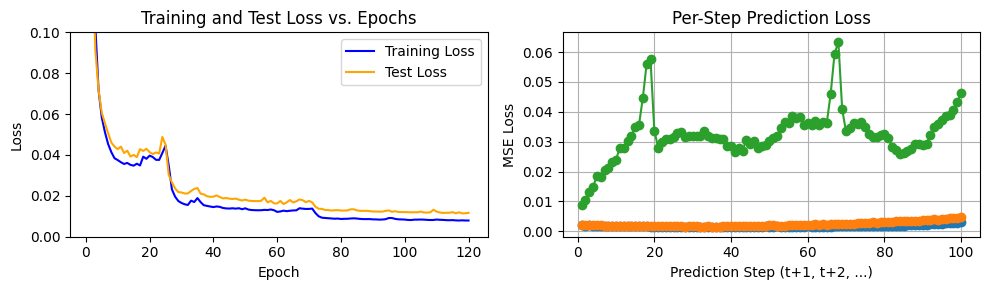

-----------------------------------------------------------------

=== Training model 41/100 ===
Epoch [20/120], Train Loss: 0.0354, Test Loss: 0.0394, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0136, Test Loss: 0.0194, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0120, Test Loss: 0.0164, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0123, Test Loss: 0.0163, Current LR: 0.00500
Epoch [100/120], Train Loss: 0.0083, Test Loss: 0.0118, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0080, Test Loss: 0.0113, Current LR: 0.00125


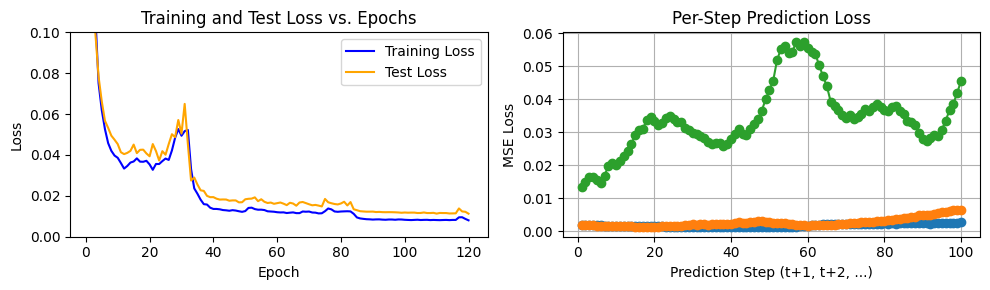

-----------------------------------------------------------------

=== Training model 42/100 ===
Epoch [20/120], Train Loss: 0.0329, Test Loss: 0.0402, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0134, Test Loss: 0.0195, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0105, Test Loss: 0.0160, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0096, Test Loss: 0.0148, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0092, Test Loss: 0.0137, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0087, Test Loss: 0.0133, Current LR: 0.00125


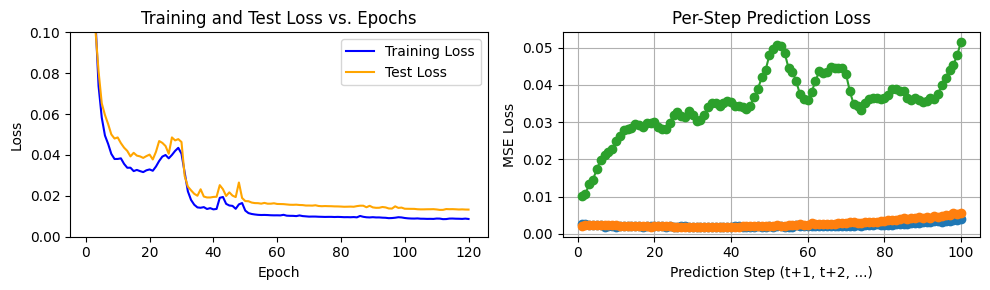

-----------------------------------------------------------------

=== Training model 43/100 ===
Epoch [20/120], Train Loss: 0.0347, Test Loss: 0.0482, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0178, Test Loss: 0.0229, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0113, Test Loss: 0.0167, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0098, Test Loss: 0.0155, Current LR: 0.00125
Epoch [100/120], Train Loss: 0.0091, Test Loss: 0.0141, Current LR: 0.00125
Epoch [120/120], Train Loss: 0.0086, Test Loss: 0.0134, Current LR: 0.00125


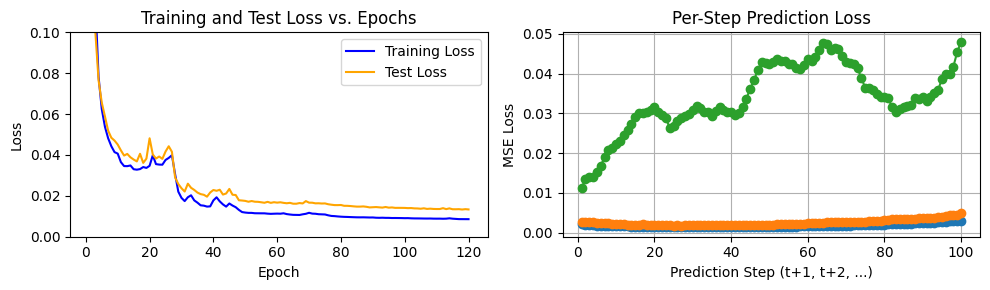

-----------------------------------------------------------------

=== Training model 44/100 ===
Epoch [20/120], Train Loss: 0.0360, Test Loss: 0.0368, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0142, Test Loss: 0.0183, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0134, Test Loss: 0.0162, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0089, Test Loss: 0.0118, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0085, Test Loss: 0.0111, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0079, Test Loss: 0.0103, Current LR: 0.00250


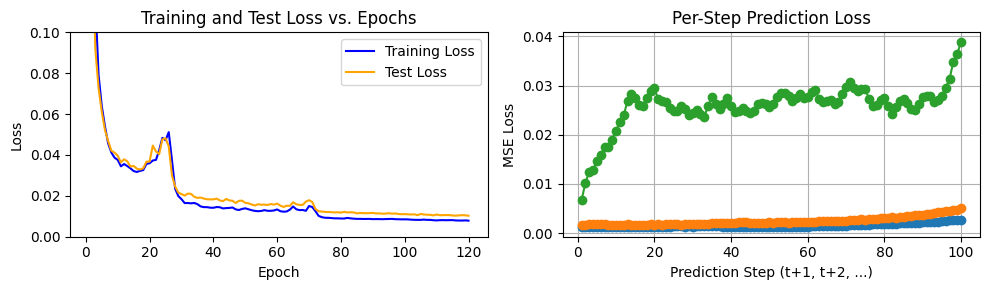

-----------------------------------------------------------------

=== Training model 45/100 ===
Epoch [20/120], Train Loss: 0.0333, Test Loss: 0.0397, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0150, Test Loss: 0.0198, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0141, Test Loss: 0.0213, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0107, Test Loss: 0.0148, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0095, Test Loss: 0.0132, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0091, Test Loss: 0.0122, Current LR: 0.00250


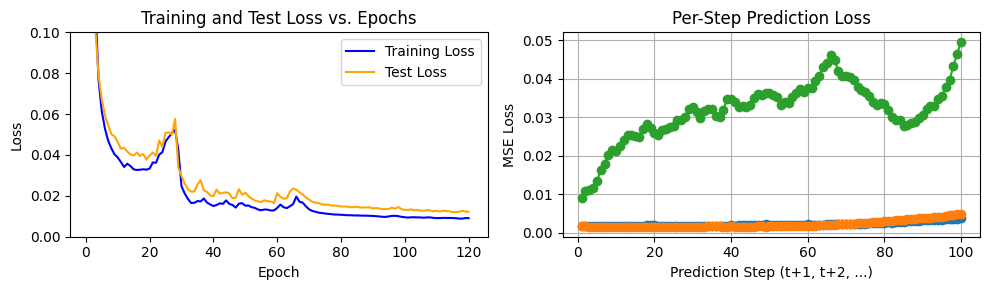

-----------------------------------------------------------------

=== Training model 46/100 ===
Epoch [20/120], Train Loss: 0.0334, Test Loss: 0.0392, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0125, Test Loss: 0.0182, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0118, Test Loss: 0.0162, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0084, Test Loss: 0.0123, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0071, Test Loss: 0.0110, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0069, Test Loss: 0.0104, Current LR: 0.00250


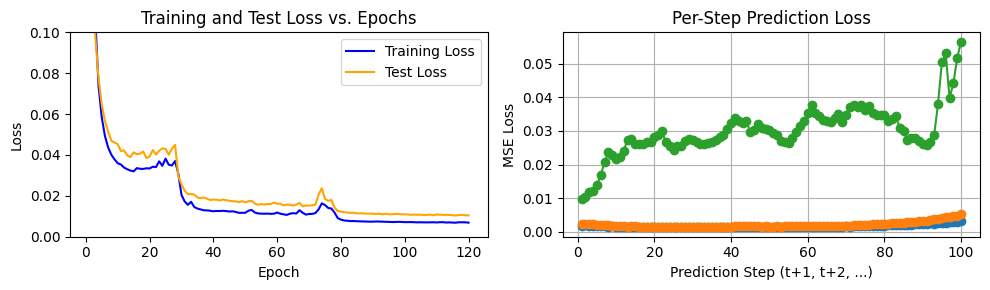

-----------------------------------------------------------------

=== Training model 47/100 ===
Epoch [20/120], Train Loss: 0.0349, Test Loss: 0.0398, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0150, Test Loss: 0.0204, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0155, Test Loss: 0.0190, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0158, Test Loss: 0.0210, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0081, Test Loss: 0.0129, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0077, Test Loss: 0.0123, Current LR: 0.00250


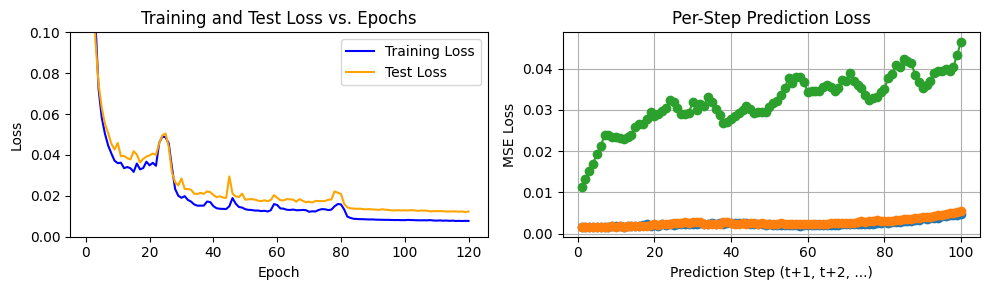

-----------------------------------------------------------------

=== Training model 48/100 ===
Epoch [20/120], Train Loss: 0.0361, Test Loss: 0.0427, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0142, Test Loss: 0.0191, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0137, Test Loss: 0.0173, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0159, Test Loss: 0.0200, Current LR: 0.00500
Epoch [100/120], Train Loss: 0.0081, Test Loss: 0.0112, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0075, Test Loss: 0.0106, Current LR: 0.00250


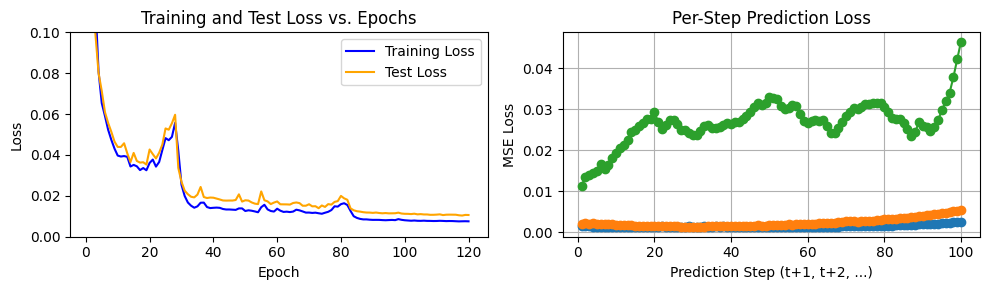

-----------------------------------------------------------------

=== Training model 49/100 ===
Epoch [20/120], Train Loss: 0.0336, Test Loss: 0.0382, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0140, Test Loss: 0.0189, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0105, Test Loss: 0.0156, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0097, Test Loss: 0.0142, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0089, Test Loss: 0.0130, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0086, Test Loss: 0.0123, Current LR: 0.00250


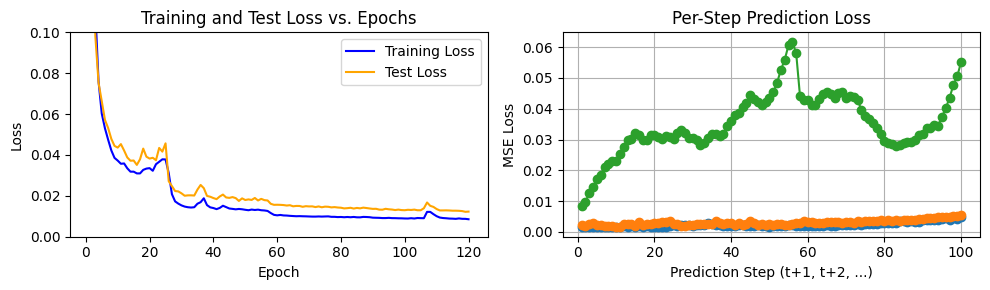

-----------------------------------------------------------------

=== Training model 50/100 ===
Epoch [20/120], Train Loss: 0.0378, Test Loss: 0.0357, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0151, Test Loss: 0.0172, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0147, Test Loss: 0.0215, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0096, Test Loss: 0.0116, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0086, Test Loss: 0.0105, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0082, Test Loss: 0.0097, Current LR: 0.00250


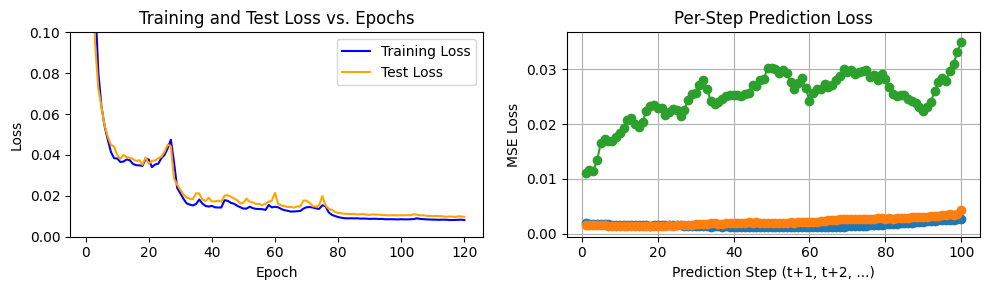

-----------------------------------------------------------------

=== Training model 51/100 ===
Epoch [20/120], Train Loss: 0.0354, Test Loss: 0.0363, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0135, Test Loss: 0.0179, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0121, Test Loss: 0.0151, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0085, Test Loss: 0.0117, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0075, Test Loss: 0.0107, Current LR: 0.00125
Epoch [120/120], Train Loss: 0.0073, Test Loss: 0.0102, Current LR: 0.00125


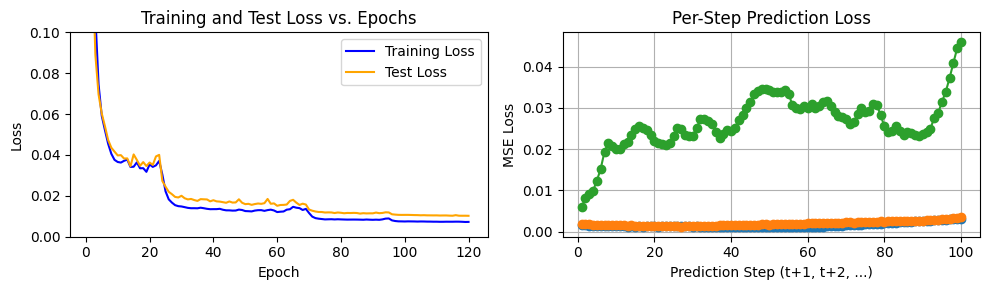

-----------------------------------------------------------------

=== Training model 52/100 ===
Epoch [20/120], Train Loss: 0.0357, Test Loss: 0.0378, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0143, Test Loss: 0.0197, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0112, Test Loss: 0.0169, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0103, Test Loss: 0.0161, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0096, Test Loss: 0.0148, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0079, Test Loss: 0.0129, Current LR: 0.00125


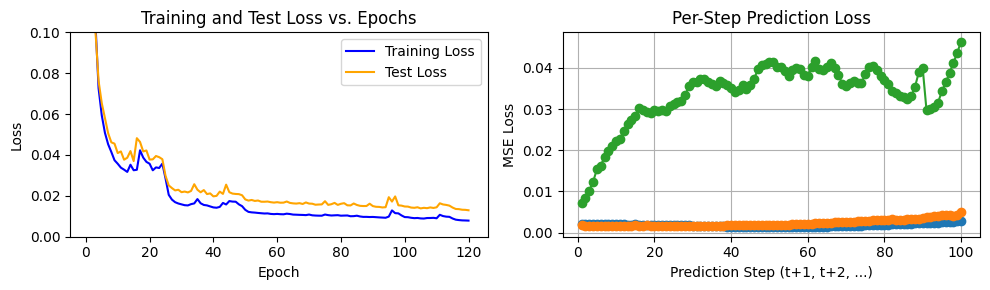

-----------------------------------------------------------------

=== Training model 53/100 ===
Epoch [20/120], Train Loss: 0.0374, Test Loss: 0.0420, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0129, Test Loss: 0.0187, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0126, Test Loss: 0.0170, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0090, Test Loss: 0.0138, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0084, Test Loss: 0.0127, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0081, Test Loss: 0.0121, Current LR: 0.00250


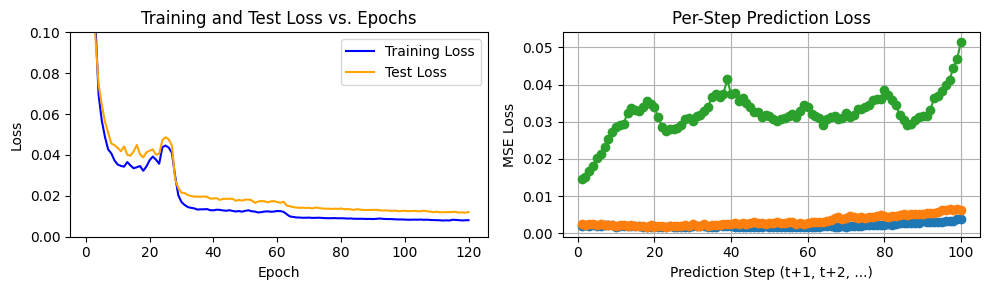

-----------------------------------------------------------------

=== Training model 54/100 ===
Epoch [20/120], Train Loss: 0.0334, Test Loss: 0.0379, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0159, Test Loss: 0.0213, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0119, Test Loss: 0.0164, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0088, Test Loss: 0.0132, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0083, Test Loss: 0.0125, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0074, Test Loss: 0.0112, Current LR: 0.00125


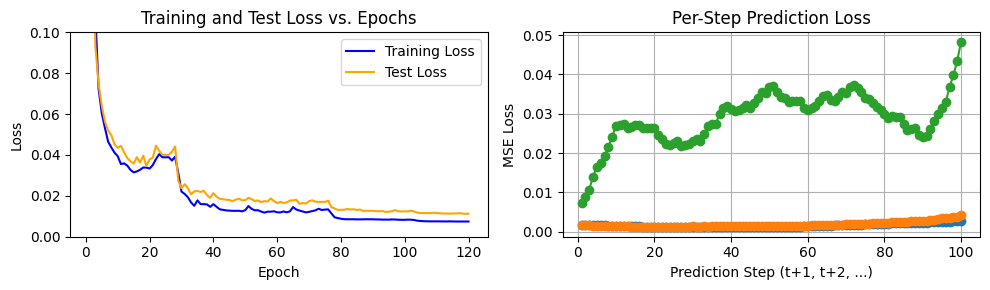

-----------------------------------------------------------------

=== Training model 55/100 ===
Epoch [20/120], Train Loss: 0.0336, Test Loss: 0.0351, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0155, Test Loss: 0.0188, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0120, Test Loss: 0.0151, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0091, Test Loss: 0.0122, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0084, Test Loss: 0.0113, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0081, Test Loss: 0.0107, Current LR: 0.00250


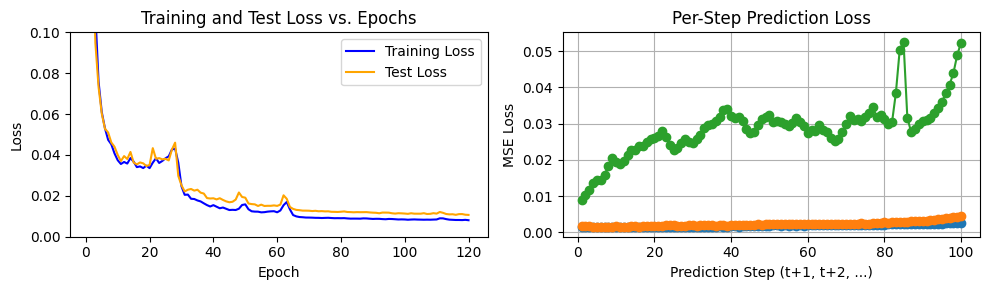

-----------------------------------------------------------------

=== Training model 56/100 ===
Epoch [20/120], Train Loss: 0.0356, Test Loss: 0.0414, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0144, Test Loss: 0.0187, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0117, Test Loss: 0.0155, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0088, Test Loss: 0.0122, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0083, Test Loss: 0.0115, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0081, Test Loss: 0.0110, Current LR: 0.00250


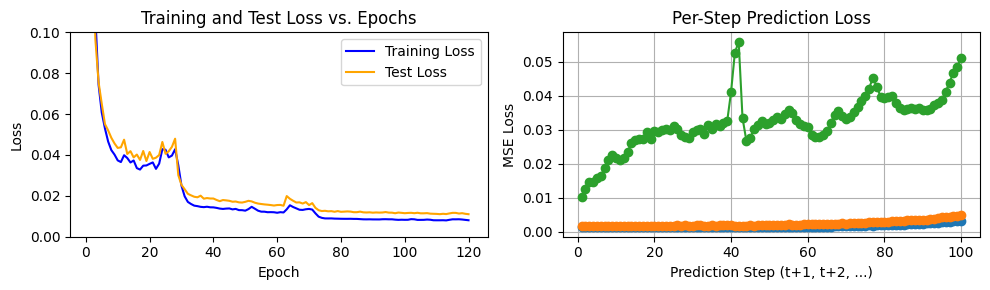

-----------------------------------------------------------------

=== Training model 57/100 ===
Epoch [20/120], Train Loss: 0.0322, Test Loss: 0.0364, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0143, Test Loss: 0.0179, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0123, Test Loss: 0.0158, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0094, Test Loss: 0.0127, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0083, Test Loss: 0.0112, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0077, Test Loss: 0.0106, Current LR: 0.00250


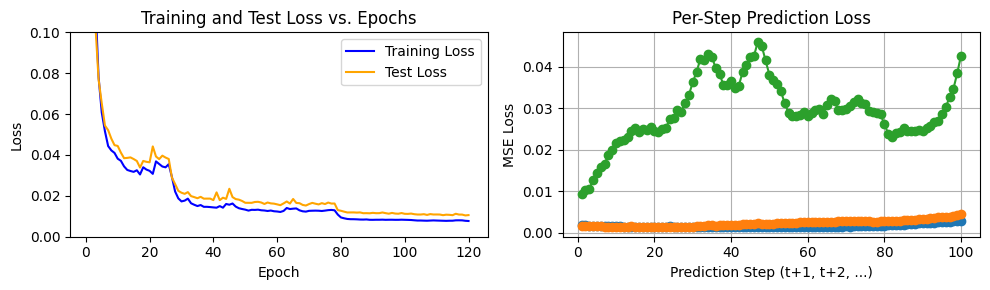

-----------------------------------------------------------------

=== Training model 58/100 ===
Epoch [20/120], Train Loss: 0.0311, Test Loss: 0.0416, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0149, Test Loss: 0.0211, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0147, Test Loss: 0.0204, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0116, Test Loss: 0.0171, Current LR: 0.00125
Epoch [100/120], Train Loss: 0.0092, Test Loss: 0.0139, Current LR: 0.00125
Epoch [120/120], Train Loss: 0.0087, Test Loss: 0.0128, Current LR: 0.00125


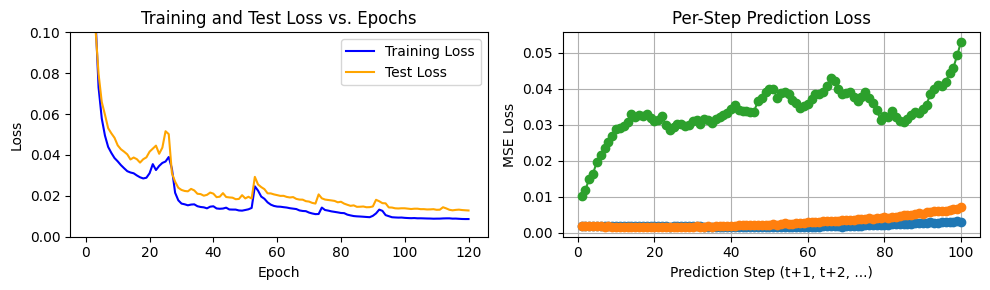

-----------------------------------------------------------------

=== Training model 59/100 ===
Epoch [20/120], Train Loss: 0.0310, Test Loss: 0.0326, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0133, Test Loss: 0.0170, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0114, Test Loss: 0.0146, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0096, Test Loss: 0.0132, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0092, Test Loss: 0.0127, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0086, Test Loss: 0.0119, Current LR: 0.00250


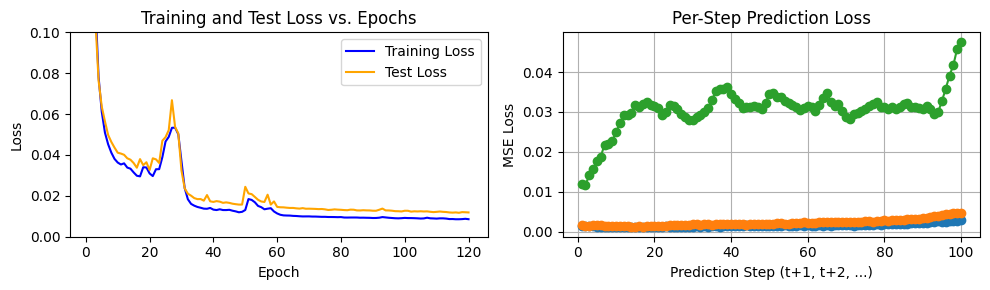

-----------------------------------------------------------------

=== Training model 60/100 ===
Epoch [20/120], Train Loss: 0.0454, Test Loss: 0.0454, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0183, Test Loss: 0.0219, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0108, Test Loss: 0.0157, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0105, Test Loss: 0.0140, Current LR: 0.00500
Epoch [100/120], Train Loss: 0.0073, Test Loss: 0.0106, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0071, Test Loss: 0.0100, Current LR: 0.00250


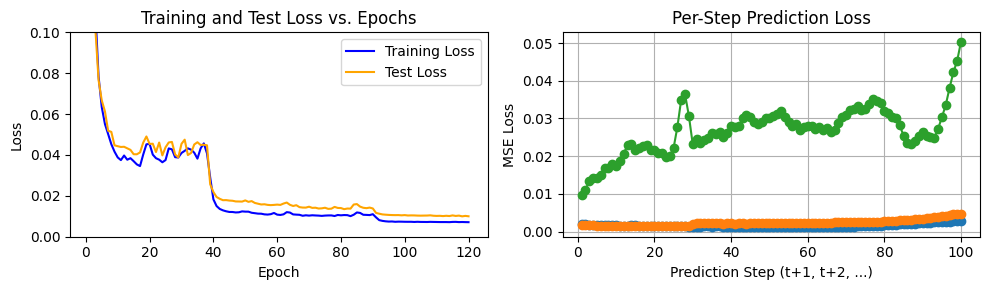

-----------------------------------------------------------------

=== Training model 61/100 ===
Epoch [20/120], Train Loss: 0.0388, Test Loss: 0.0442, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0145, Test Loss: 0.0187, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0122, Test Loss: 0.0154, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0090, Test Loss: 0.0125, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0087, Test Loss: 0.0114, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0082, Test Loss: 0.0111, Current LR: 0.00125


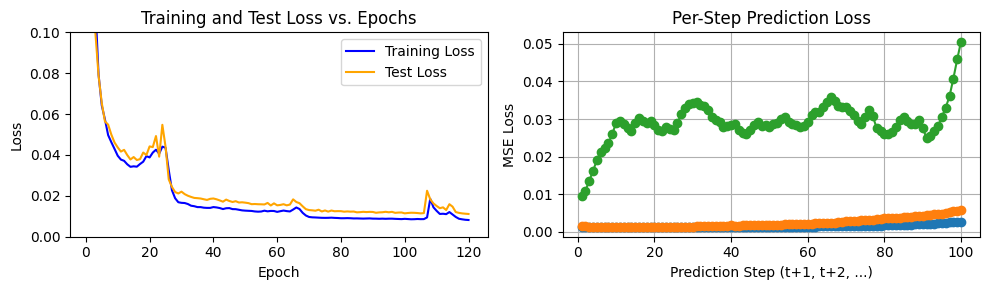

-----------------------------------------------------------------

=== Training model 62/100 ===
Epoch [20/120], Train Loss: 0.0367, Test Loss: 0.0412, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0131, Test Loss: 0.0185, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0118, Test Loss: 0.0155, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0097, Test Loss: 0.0131, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0085, Test Loss: 0.0122, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0082, Test Loss: 0.0112, Current LR: 0.00250


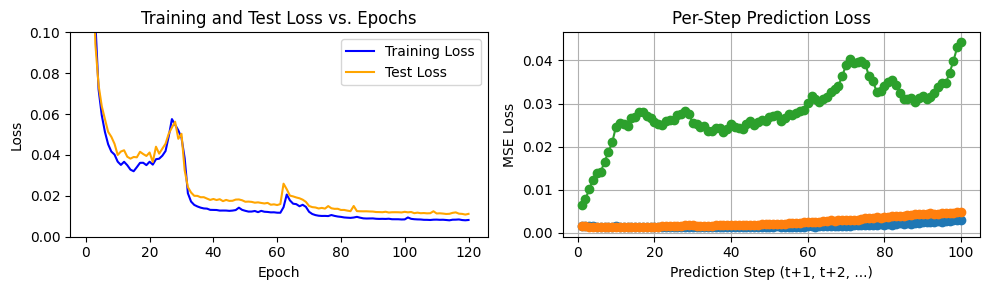

-----------------------------------------------------------------

=== Training model 63/100 ===
Epoch [20/120], Train Loss: 0.0333, Test Loss: 0.0417, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0137, Test Loss: 0.0197, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0134, Test Loss: 0.0179, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0091, Test Loss: 0.0144, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0085, Test Loss: 0.0130, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0073, Test Loss: 0.0113, Current LR: 0.00125


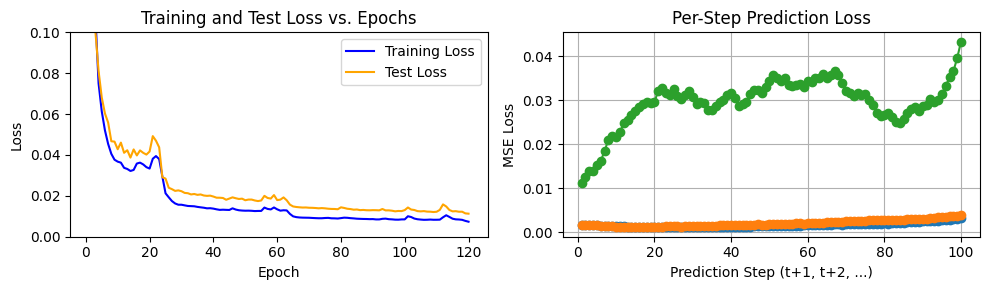

-----------------------------------------------------------------

=== Training model 64/100 ===
Epoch [20/120], Train Loss: 0.0311, Test Loss: 0.0375, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0142, Test Loss: 0.0202, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0154, Test Loss: 0.0190, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0093, Test Loss: 0.0132, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0092, Test Loss: 0.0130, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0081, Test Loss: 0.0122, Current LR: 0.00125


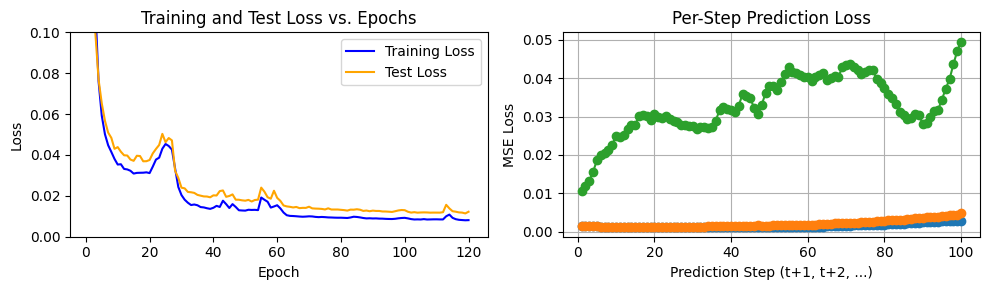

-----------------------------------------------------------------

=== Training model 65/100 ===
Epoch [20/120], Train Loss: 0.0362, Test Loss: 0.0398, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0144, Test Loss: 0.0180, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0169, Test Loss: 0.0196, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0107, Test Loss: 0.0149, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0095, Test Loss: 0.0135, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0089, Test Loss: 0.0125, Current LR: 0.00250


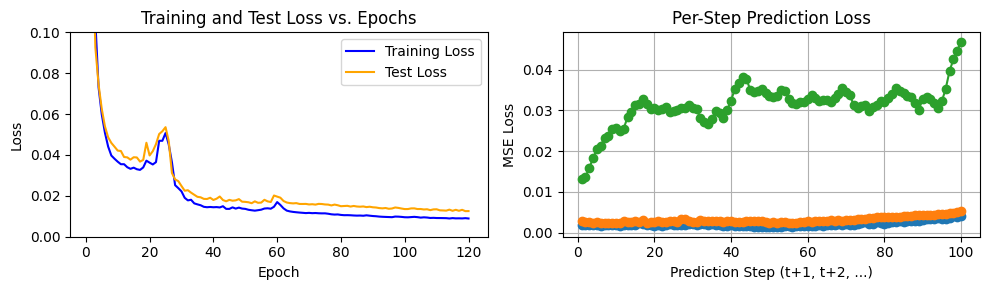

-----------------------------------------------------------------

=== Training model 66/100 ===
Epoch [20/120], Train Loss: 0.0349, Test Loss: 0.0391, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0150, Test Loss: 0.0192, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0113, Test Loss: 0.0168, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0116, Test Loss: 0.0149, Current LR: 0.00500
Epoch [100/120], Train Loss: 0.0077, Test Loss: 0.0117, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0072, Test Loss: 0.0111, Current LR: 0.00250


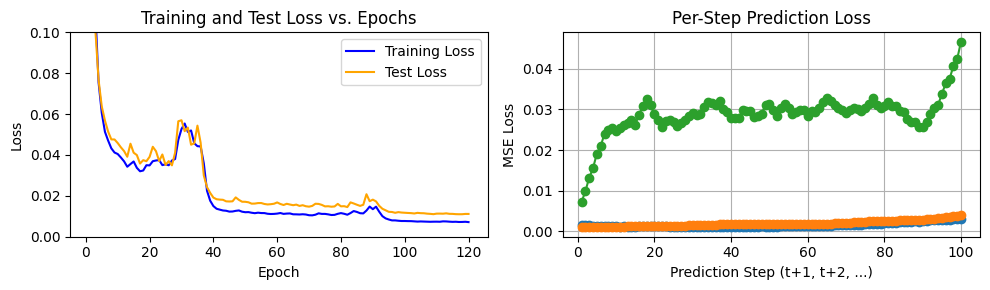

-----------------------------------------------------------------

=== Training model 67/100 ===
Epoch [20/120], Train Loss: 0.0340, Test Loss: 0.0380, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0161, Test Loss: 0.0202, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0138, Test Loss: 0.0181, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0177, Test Loss: 0.0202, Current LR: 0.00500
Epoch [100/120], Train Loss: 0.0089, Test Loss: 0.0128, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0086, Test Loss: 0.0125, Current LR: 0.00250


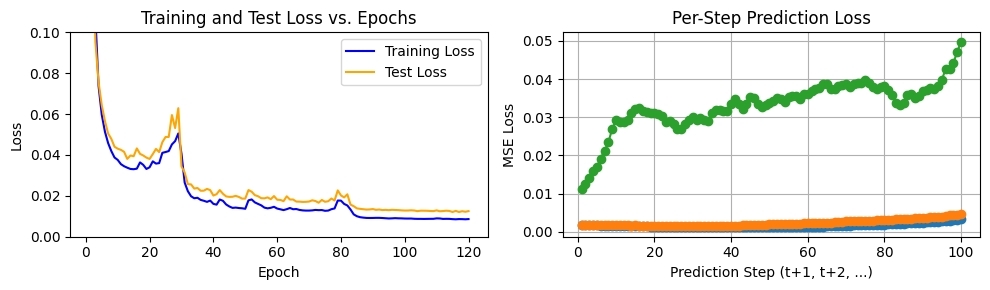

-----------------------------------------------------------------

=== Training model 68/100 ===
Epoch [20/120], Train Loss: 0.0323, Test Loss: 0.0363, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0129, Test Loss: 0.0174, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0106, Test Loss: 0.0153, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0097, Test Loss: 0.0140, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0091, Test Loss: 0.0131, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0088, Test Loss: 0.0122, Current LR: 0.00250


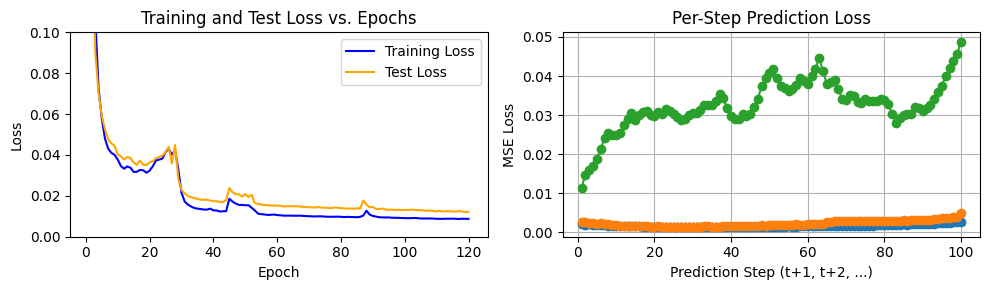

-----------------------------------------------------------------

=== Training model 69/100 ===
Epoch [20/120], Train Loss: 0.0304, Test Loss: 0.0400, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0141, Test Loss: 0.0210, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0119, Test Loss: 0.0194, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0106, Test Loss: 0.0169, Current LR: 0.00125
Epoch [100/120], Train Loss: 0.0087, Test Loss: 0.0139, Current LR: 0.00125
Epoch [120/120], Train Loss: 0.0082, Test Loss: 0.0129, Current LR: 0.00125


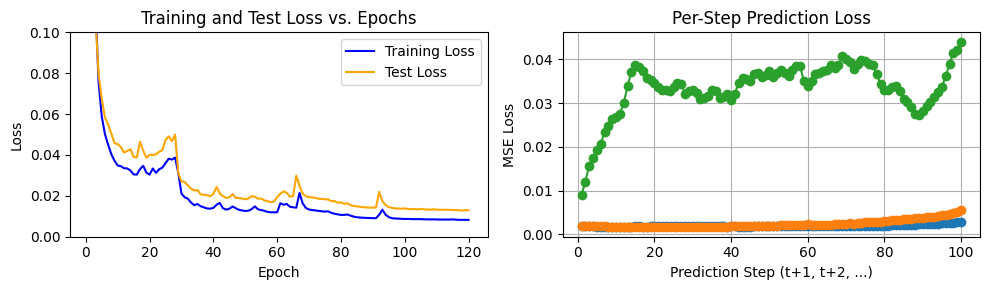

-----------------------------------------------------------------

=== Training model 70/100 ===
Epoch [20/120], Train Loss: 0.0337, Test Loss: 0.0367, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0169, Test Loss: 0.0202, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0110, Test Loss: 0.0149, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0109, Test Loss: 0.0138, Current LR: 0.00500
Epoch [100/120], Train Loss: 0.0078, Test Loss: 0.0110, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0075, Test Loss: 0.0105, Current LR: 0.00250


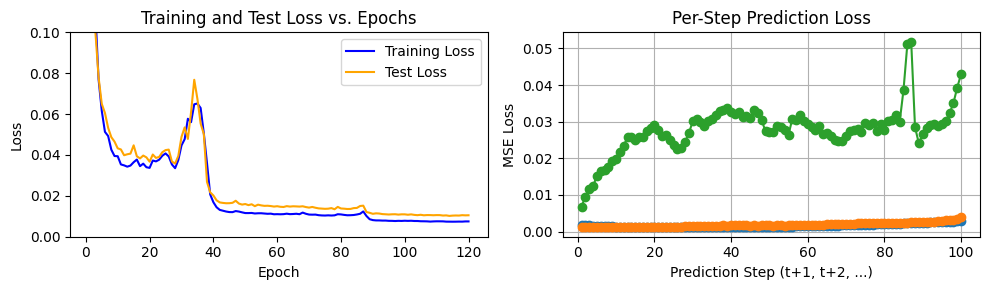

-----------------------------------------------------------------

=== Training model 71/100 ===
Epoch [20/120], Train Loss: 0.0334, Test Loss: 0.0387, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0139, Test Loss: 0.0178, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0123, Test Loss: 0.0161, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0095, Test Loss: 0.0128, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0086, Test Loss: 0.0121, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0084, Test Loss: 0.0115, Current LR: 0.00250


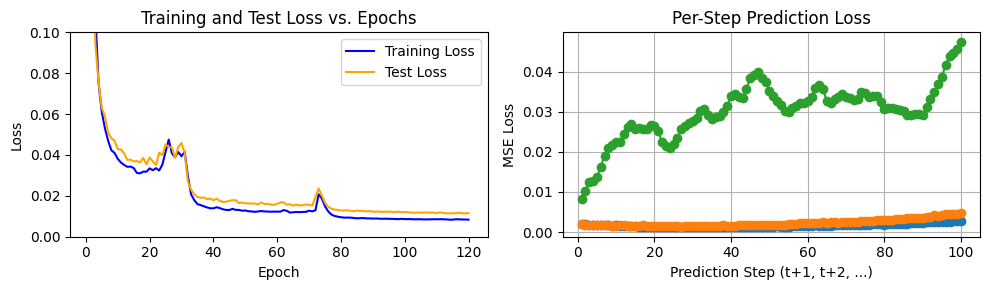

-----------------------------------------------------------------

=== Training model 72/100 ===
Epoch [20/120], Train Loss: 0.0322, Test Loss: 0.0463, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0134, Test Loss: 0.0188, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0183, Test Loss: 0.0217, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0103, Test Loss: 0.0138, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0094, Test Loss: 0.0126, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0091, Test Loss: 0.0118, Current LR: 0.00250


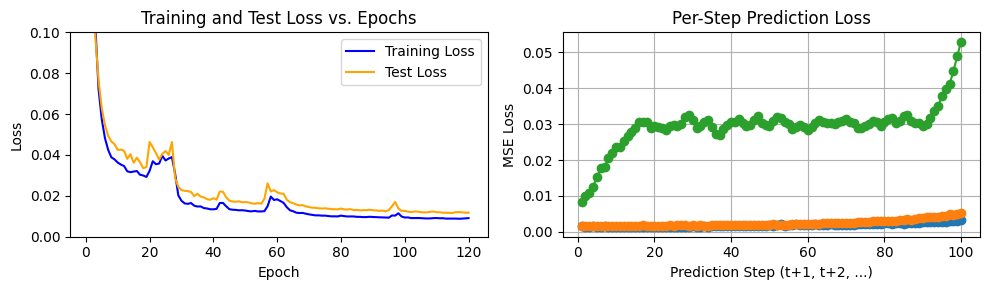

-----------------------------------------------------------------

=== Training model 73/100 ===
Epoch [20/120], Train Loss: 0.0376, Test Loss: 0.0397, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0183, Test Loss: 0.0218, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0141, Test Loss: 0.0177, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0101, Test Loss: 0.0135, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0093, Test Loss: 0.0125, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0088, Test Loss: 0.0119, Current LR: 0.00250


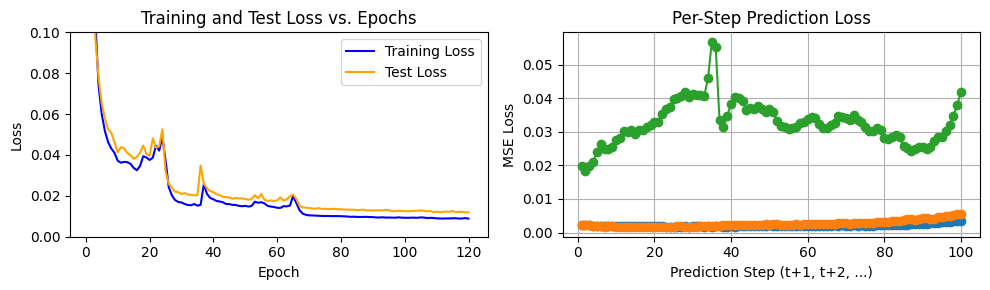

-----------------------------------------------------------------

=== Training model 74/100 ===
Epoch [20/120], Train Loss: 0.0355, Test Loss: 0.0438, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0140, Test Loss: 0.0219, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0117, Test Loss: 0.0170, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0083, Test Loss: 0.0128, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0078, Test Loss: 0.0121, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0076, Test Loss: 0.0115, Current LR: 0.00250


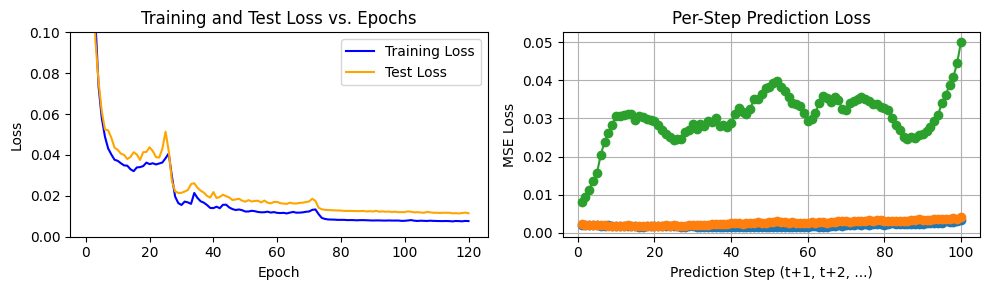

-----------------------------------------------------------------

=== Training model 75/100 ===
Epoch [20/120], Train Loss: 0.0345, Test Loss: 0.0396, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0169, Test Loss: 0.0229, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0147, Test Loss: 0.0196, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0096, Test Loss: 0.0141, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0086, Test Loss: 0.0128, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0081, Test Loss: 0.0118, Current LR: 0.00250


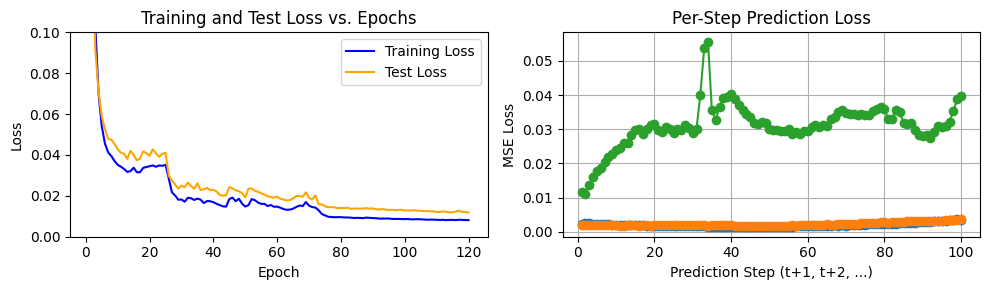

-----------------------------------------------------------------

=== Training model 76/100 ===
Epoch [20/120], Train Loss: 0.0372, Test Loss: 0.0377, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0166, Test Loss: 0.0199, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0134, Test Loss: 0.0156, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0093, Test Loss: 0.0116, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0088, Test Loss: 0.0108, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0085, Test Loss: 0.0105, Current LR: 0.00250


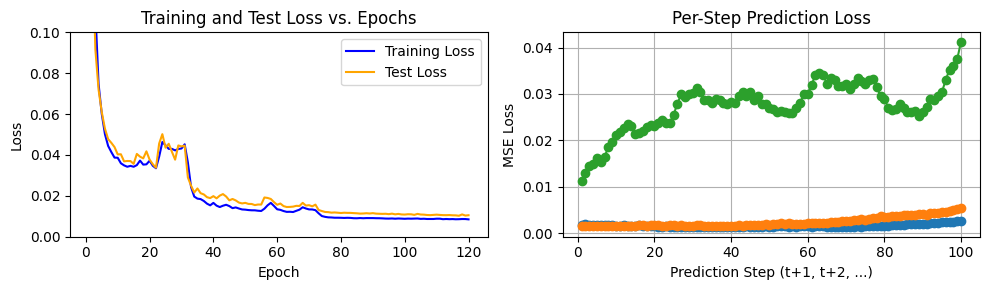

-----------------------------------------------------------------

=== Training model 77/100 ===
Epoch [20/120], Train Loss: 0.0342, Test Loss: 0.0392, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0166, Test Loss: 0.0204, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0125, Test Loss: 0.0159, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0091, Test Loss: 0.0126, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0090, Test Loss: 0.0122, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0082, Test Loss: 0.0111, Current LR: 0.00250


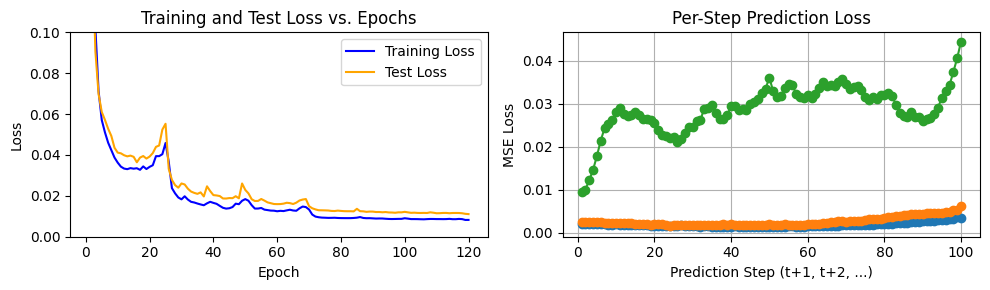

-----------------------------------------------------------------

=== Training model 78/100 ===
Epoch [20/120], Train Loss: 0.0304, Test Loss: 0.0336, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0160, Test Loss: 0.0180, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0114, Test Loss: 0.0142, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0084, Test Loss: 0.0118, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0078, Test Loss: 0.0112, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0076, Test Loss: 0.0111, Current LR: 0.00250


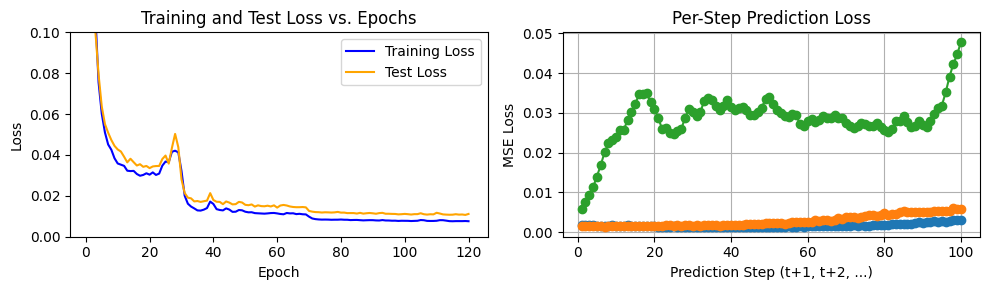

-----------------------------------------------------------------

=== Training model 79/100 ===
Epoch [20/120], Train Loss: 0.0305, Test Loss: 0.0341, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0128, Test Loss: 0.0173, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0164, Test Loss: 0.0229, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0090, Test Loss: 0.0124, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0083, Test Loss: 0.0117, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0072, Test Loss: 0.0103, Current LR: 0.00125


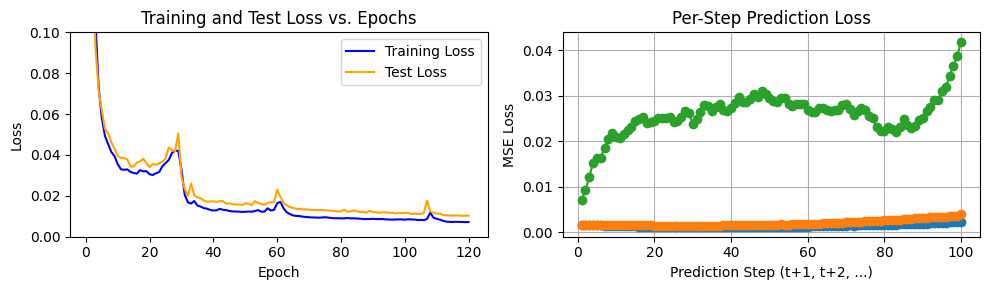

-----------------------------------------------------------------

=== Training model 80/100 ===
Epoch [20/120], Train Loss: 0.0296, Test Loss: 0.0385, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0153, Test Loss: 0.0204, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0110, Test Loss: 0.0162, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0084, Test Loss: 0.0131, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0078, Test Loss: 0.0124, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0074, Test Loss: 0.0109, Current LR: 0.00250


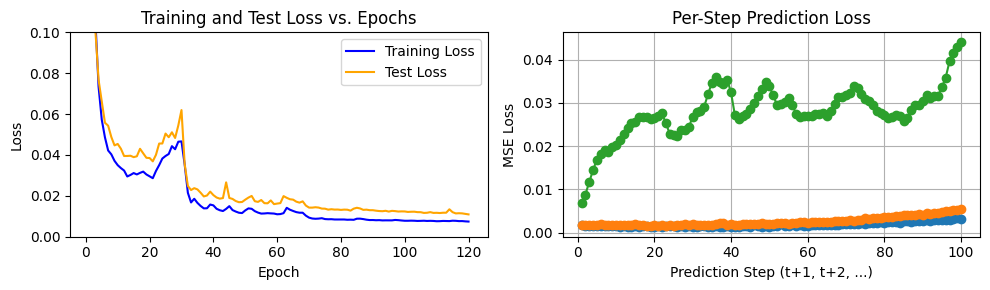

-----------------------------------------------------------------

=== Training model 81/100 ===
Epoch [20/120], Train Loss: 0.0354, Test Loss: 0.0432, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0185, Test Loss: 0.0222, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0103, Test Loss: 0.0149, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0094, Test Loss: 0.0136, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0092, Test Loss: 0.0129, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0081, Test Loss: 0.0115, Current LR: 0.00250


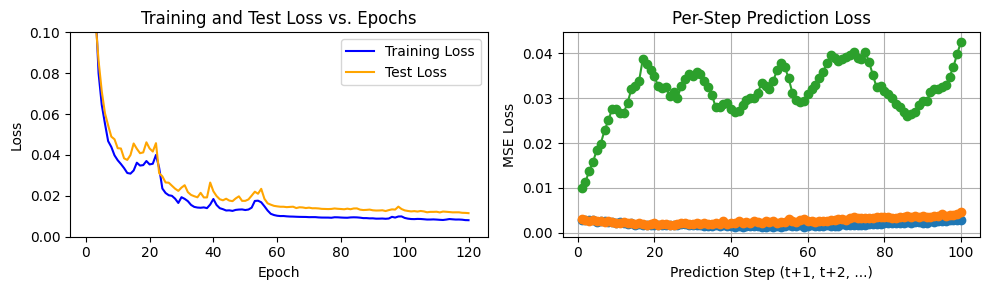

-----------------------------------------------------------------

=== Training model 82/100 ===
Epoch [20/120], Train Loss: 0.0308, Test Loss: 0.0389, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0157, Test Loss: 0.0224, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0123, Test Loss: 0.0180, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0105, Test Loss: 0.0150, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0095, Test Loss: 0.0135, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0090, Test Loss: 0.0126, Current LR: 0.00250


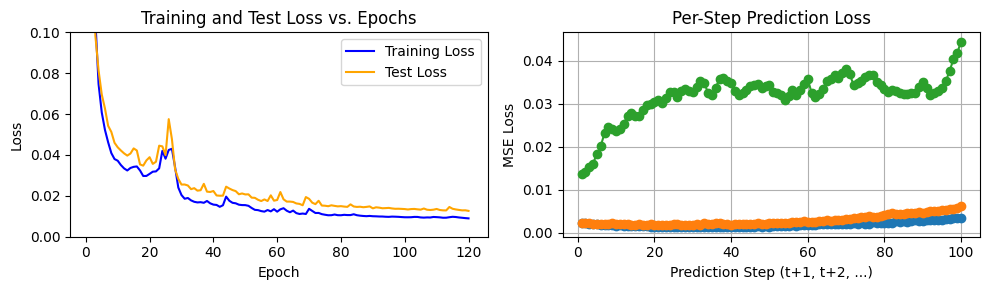

-----------------------------------------------------------------

=== Training model 83/100 ===
Epoch [20/120], Train Loss: 0.0346, Test Loss: 0.0353, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0136, Test Loss: 0.0207, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0122, Test Loss: 0.0152, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0084, Test Loss: 0.0114, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0079, Test Loss: 0.0105, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0072, Test Loss: 0.0097, Current LR: 0.00250


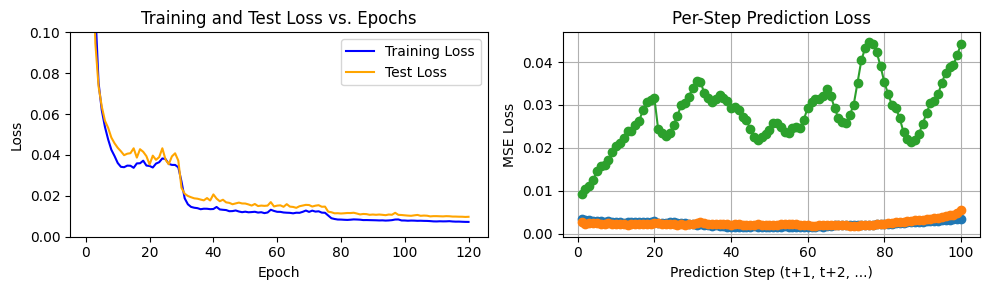

-----------------------------------------------------------------

=== Training model 84/100 ===
Epoch [20/120], Train Loss: 0.0389, Test Loss: 0.0434, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0140, Test Loss: 0.0175, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0145, Test Loss: 0.0172, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0097, Test Loss: 0.0128, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0089, Test Loss: 0.0118, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0085, Test Loss: 0.0115, Current LR: 0.00250


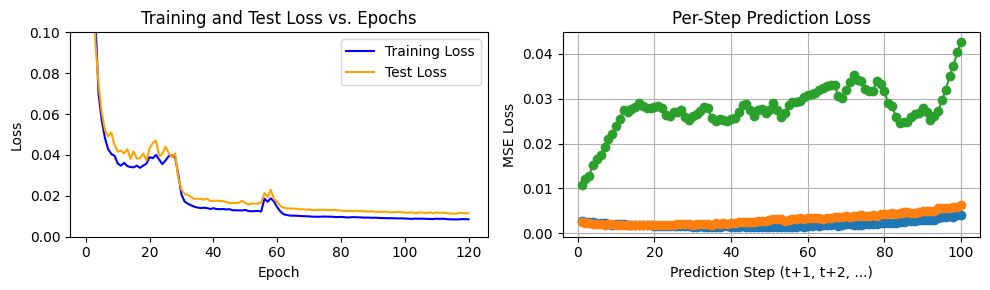

-----------------------------------------------------------------

=== Training model 85/100 ===
Epoch [20/120], Train Loss: 0.0369, Test Loss: 0.0406, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0146, Test Loss: 0.0194, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0123, Test Loss: 0.0165, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0087, Test Loss: 0.0122, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0082, Test Loss: 0.0117, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0069, Test Loss: 0.0102, Current LR: 0.00125


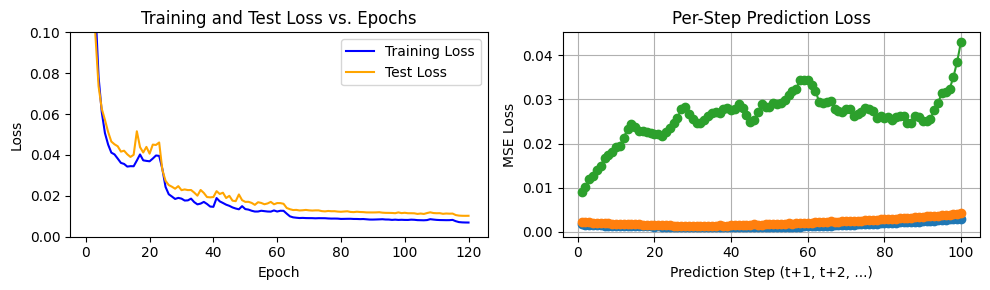

-----------------------------------------------------------------

=== Training model 86/100 ===
Epoch [20/120], Train Loss: 0.0386, Test Loss: 0.0440, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0153, Test Loss: 0.0183, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0143, Test Loss: 0.0180, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0097, Test Loss: 0.0137, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0089, Test Loss: 0.0120, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0082, Test Loss: 0.0111, Current LR: 0.00250


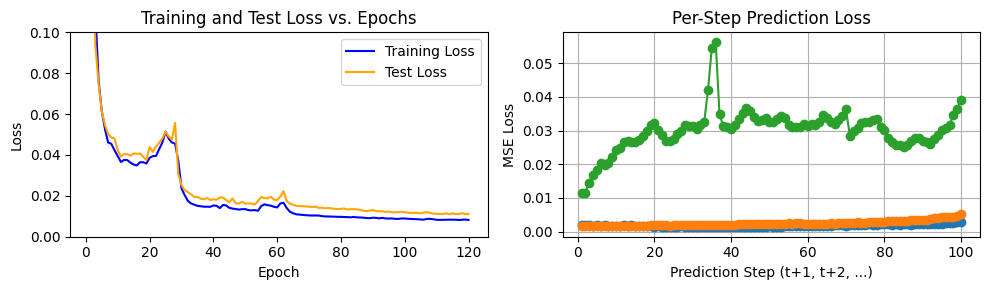

-----------------------------------------------------------------

=== Training model 87/100 ===
Epoch [20/120], Train Loss: 0.0381, Test Loss: 0.0429, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0145, Test Loss: 0.0206, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0135, Test Loss: 0.0185, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0094, Test Loss: 0.0142, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0089, Test Loss: 0.0134, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0076, Test Loss: 0.0119, Current LR: 0.00125


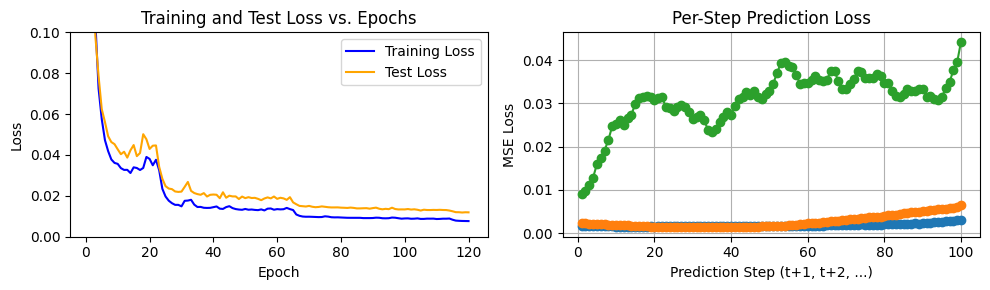

-----------------------------------------------------------------

=== Training model 88/100 ===
Epoch [20/120], Train Loss: 0.0392, Test Loss: 0.0462, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0137, Test Loss: 0.0197, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0119, Test Loss: 0.0172, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0083, Test Loss: 0.0134, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0077, Test Loss: 0.0124, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0077, Test Loss: 0.0117, Current LR: 0.00250


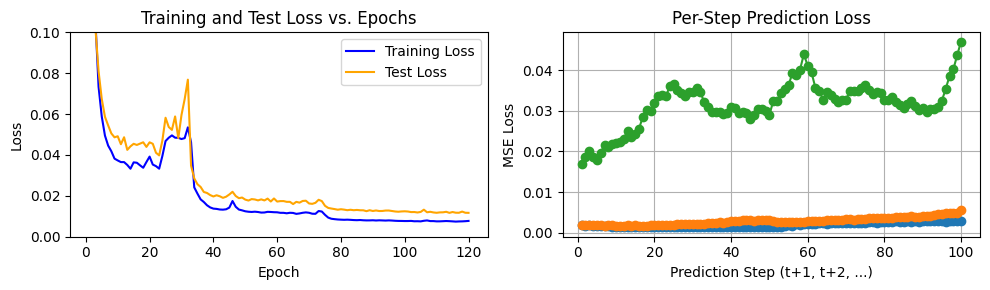

-----------------------------------------------------------------

=== Training model 89/100 ===
Epoch [20/120], Train Loss: 0.0350, Test Loss: 0.0413, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0139, Test Loss: 0.0190, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0143, Test Loss: 0.0176, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0114, Test Loss: 0.0145, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0077, Test Loss: 0.0114, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0075, Test Loss: 0.0110, Current LR: 0.00250


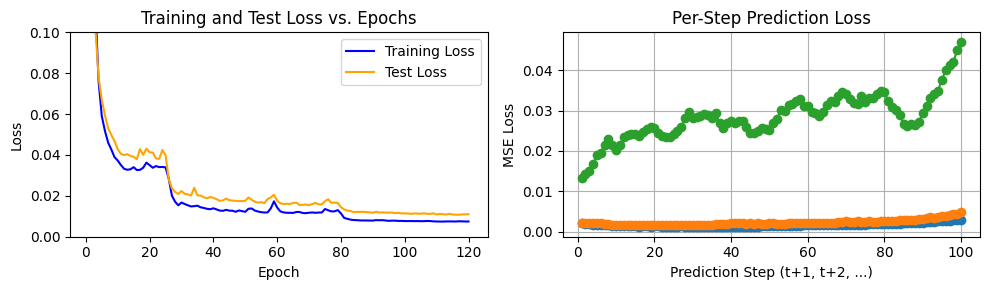

-----------------------------------------------------------------

=== Training model 90/100 ===
Epoch [20/120], Train Loss: 0.0372, Test Loss: 0.0440, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0137, Test Loss: 0.0214, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0126, Test Loss: 0.0189, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0092, Test Loss: 0.0166, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0086, Test Loss: 0.0153, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0080, Test Loss: 0.0140, Current LR: 0.00250


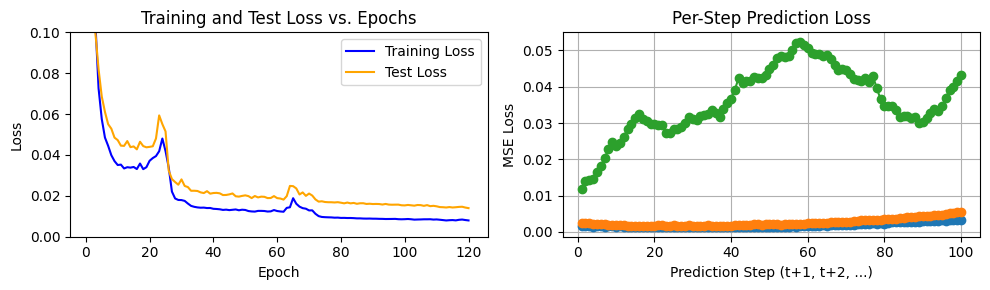

-----------------------------------------------------------------

=== Training model 91/100 ===
Epoch [20/120], Train Loss: 0.0319, Test Loss: 0.0360, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0130, Test Loss: 0.0182, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0119, Test Loss: 0.0167, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0115, Test Loss: 0.0164, Current LR: 0.00500
Epoch [100/120], Train Loss: 0.0076, Test Loss: 0.0118, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0073, Test Loss: 0.0113, Current LR: 0.00250


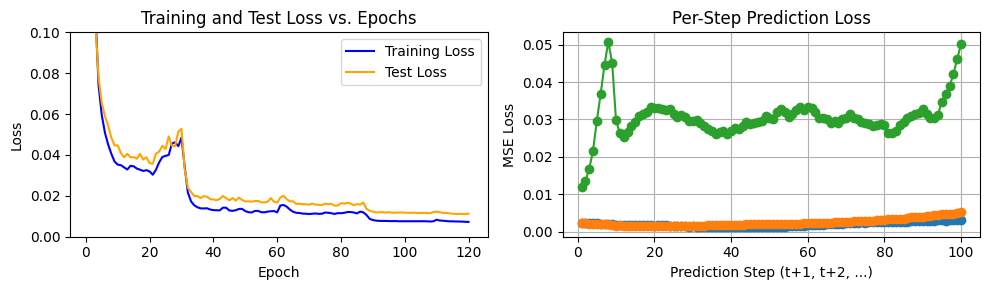

-----------------------------------------------------------------

=== Training model 92/100 ===
Epoch [20/120], Train Loss: 0.0402, Test Loss: 0.0428, Current LR: 0.00500
Epoch [40/120], Train Loss: 0.0156, Test Loss: 0.0207, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0217, Test Loss: 0.0232, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0096, Test Loss: 0.0141, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0089, Test Loss: 0.0131, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0085, Test Loss: 0.0123, Current LR: 0.00250


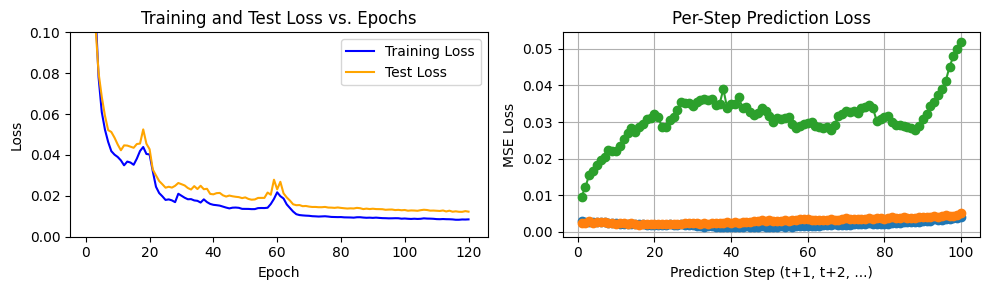

-----------------------------------------------------------------

=== Training model 93/100 ===
Epoch [20/120], Train Loss: 0.0326, Test Loss: 0.0361, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0140, Test Loss: 0.0180, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0120, Test Loss: 0.0155, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0094, Test Loss: 0.0135, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0084, Test Loss: 0.0119, Current LR: 0.00125
Epoch [120/120], Train Loss: 0.0076, Test Loss: 0.0112, Current LR: 0.00125


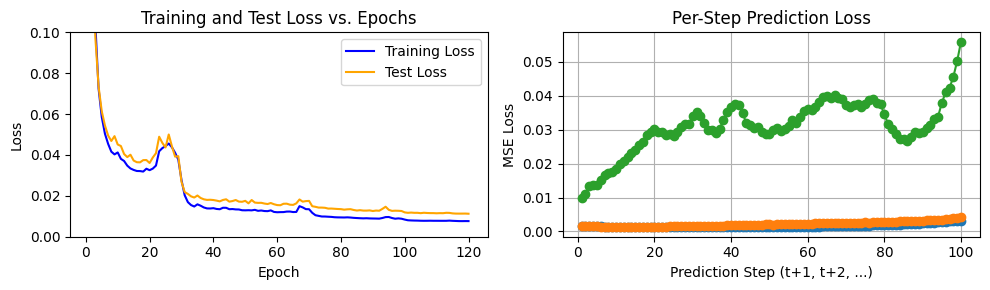

-----------------------------------------------------------------

=== Training model 94/100 ===
Epoch [20/120], Train Loss: 0.0365, Test Loss: 0.0413, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0163, Test Loss: 0.0200, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0139, Test Loss: 0.0169, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0100, Test Loss: 0.0133, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0094, Test Loss: 0.0126, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0088, Test Loss: 0.0118, Current LR: 0.00250


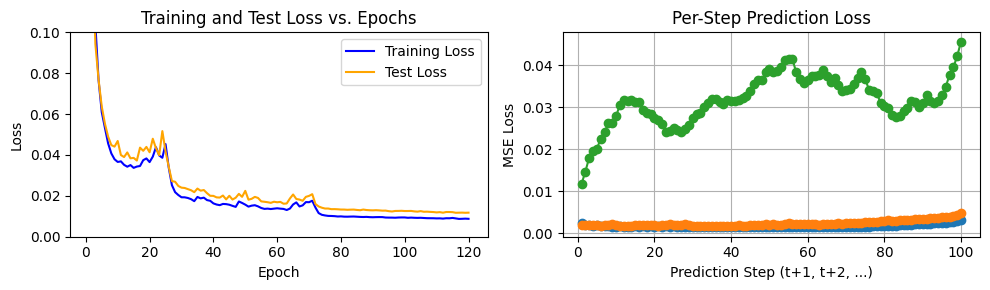

-----------------------------------------------------------------

=== Training model 95/100 ===
Epoch [20/120], Train Loss: 0.0312, Test Loss: 0.0400, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0156, Test Loss: 0.0194, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0151, Test Loss: 0.0215, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0099, Test Loss: 0.0144, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0085, Test Loss: 0.0122, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0083, Test Loss: 0.0115, Current LR: 0.00250


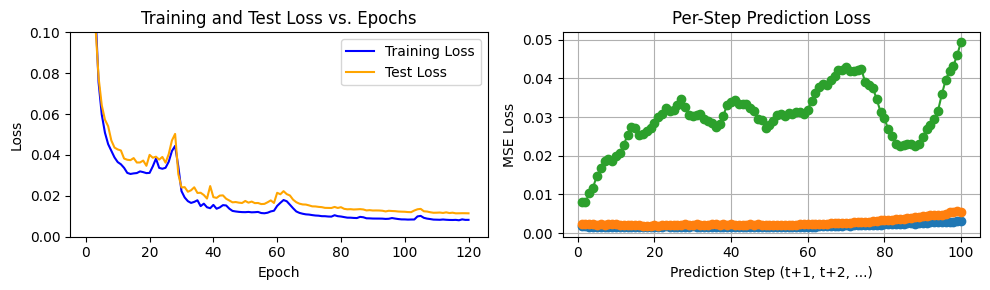

-----------------------------------------------------------------

=== Training model 96/100 ===
Epoch [20/120], Train Loss: 0.0381, Test Loss: 0.0389, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0155, Test Loss: 0.0202, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0130, Test Loss: 0.0171, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0084, Test Loss: 0.0124, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0079, Test Loss: 0.0115, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0075, Test Loss: 0.0111, Current LR: 0.00250


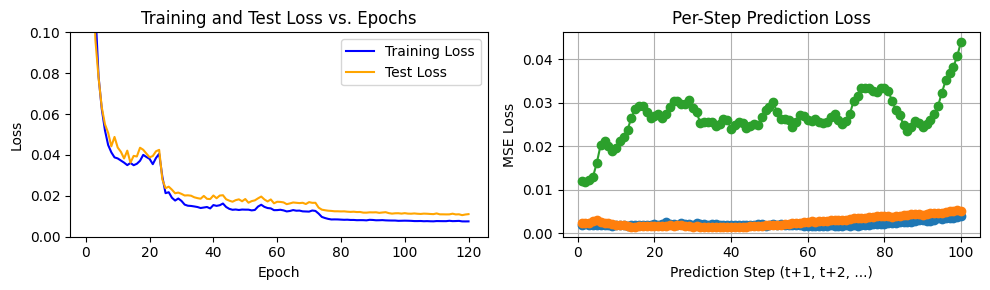

-----------------------------------------------------------------

=== Training model 97/100 ===
Epoch [20/120], Train Loss: 0.0343, Test Loss: 0.0416, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0160, Test Loss: 0.0246, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0160, Test Loss: 0.0193, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0095, Test Loss: 0.0142, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0087, Test Loss: 0.0130, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0086, Test Loss: 0.0131, Current LR: 0.00250


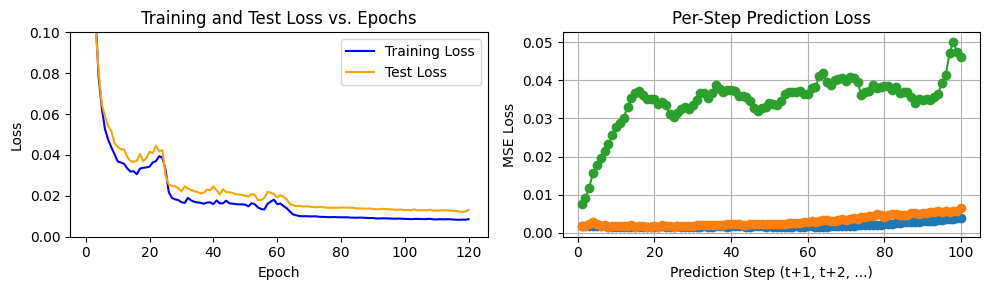

-----------------------------------------------------------------

=== Training model 98/100 ===
Epoch [20/120], Train Loss: 0.0361, Test Loss: 0.0399, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0143, Test Loss: 0.0179, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0103, Test Loss: 0.0141, Current LR: 0.00250
Epoch [80/120], Train Loss: 0.0093, Test Loss: 0.0128, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0089, Test Loss: 0.0121, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0082, Test Loss: 0.0111, Current LR: 0.00250


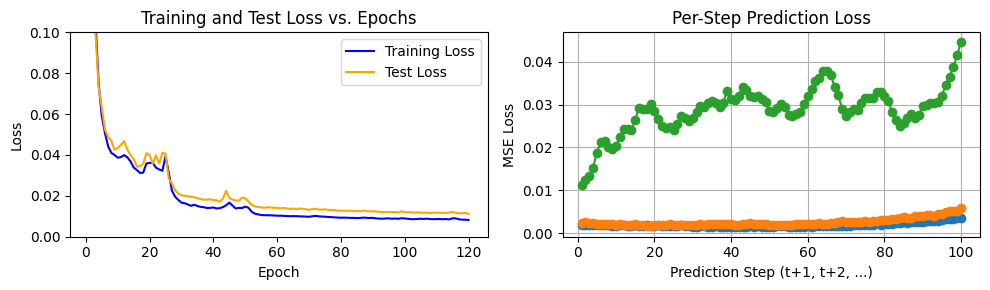

-----------------------------------------------------------------

=== Training model 99/100 ===
Epoch [20/120], Train Loss: 0.0389, Test Loss: 0.0438, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0141, Test Loss: 0.0195, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0122, Test Loss: 0.0167, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0087, Test Loss: 0.0136, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0082, Test Loss: 0.0127, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0080, Test Loss: 0.0124, Current LR: 0.00125


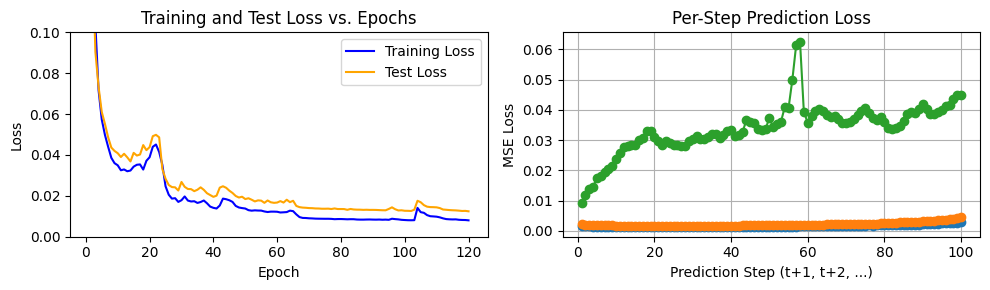

-----------------------------------------------------------------

=== Training model 100/100 ===
Epoch [20/120], Train Loss: 0.0350, Test Loss: 0.0447, Current LR: 0.01000
Epoch [40/120], Train Loss: 0.0195, Test Loss: 0.0292, Current LR: 0.00500
Epoch [60/120], Train Loss: 0.0132, Test Loss: 0.0185, Current LR: 0.00500
Epoch [80/120], Train Loss: 0.0138, Test Loss: 0.0167, Current LR: 0.00250
Epoch [100/120], Train Loss: 0.0083, Test Loss: 0.0127, Current LR: 0.00250
Epoch [120/120], Train Loss: 0.0080, Test Loss: 0.0123, Current LR: 0.00250


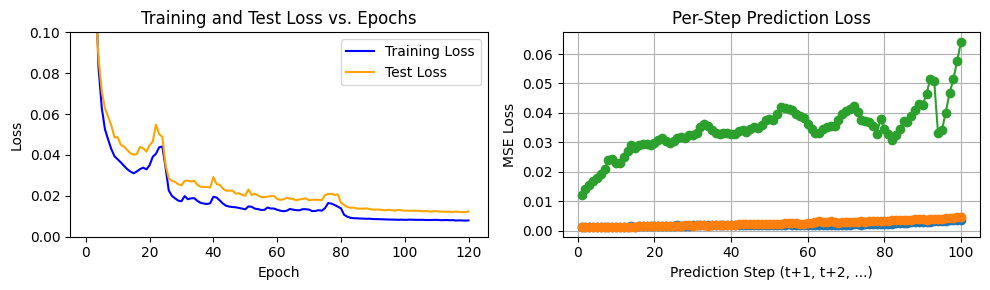


✅ Trained 100 models for ensemble.


In [ ]:
## Train Models

numerical_features_in = [
   'OD', 'Substrate', 'pO2_adjust_scaled1', 'Stirrer', 'AirFlow', 'cluster_pred_mapped'
]
n_steps_in = 20
n_steps_out = 100
n_ensemble = 100  # Number of models in the ensemble
fraction = 0.8  # 80% of original data per model
num_epochs = 120

df_features = df_combined_standard  # df_combined_minmax or df_combined_standard
target_col1 = ['OD', 'Substrate', 'pO2_adjust_scaled1']  
target_col2 = []

data_for_scale_st_sorted = data_for_scale_st.sort_values(['experiment_id', 'ProcTime']).copy()
df_features = df_features.loc[data_for_scale_st_sorted.index]
target_values = df_features[target_col1]
# target_values = pd.concat(
#     [data_for_scale_st_sorted[target_col1], df_features[target_col2]],
#     axis=1
# )

# Prepare input-output pairs
X_list = []
y_list = []
u_future_list = []

for exp_id, group_idx in data_for_scale_st_sorted.groupby('experiment_id').groups.items():
    group_features = df_features.loc[group_idx, numerical_features_in].values
    group_targets = target_values.loc[group_idx].values
    group_u_future = df_features.loc[group_idx, ['S_feed_gL', 'DilutionFactor']].values
    
    # Shift features and targets
    for i in range(len(group_features) - n_steps_in - n_steps_out + 1):
        # Take n_steps input rows and flatten into 1D
        input_seq = group_features[i:i + n_steps_in]
        target_value = group_targets[i + n_steps_in:i + n_steps_in + n_steps_out]
        u_future = group_u_future[i + n_steps_in-1:i + n_steps_in + n_steps_out-1]
        X_list.append(input_seq)
        y_list.append(target_value)
        u_future_list.append(u_future)

X_array = np.array(X_list)
y_array = np.array(y_list).reshape(-1, n_steps_out, y_list[0].shape[-1])
u_future_array = np.array(u_future_list)
print(X_array.shape[-1])
full_dataset = list(zip(X_array, u_future_array, y_array))

ensemble_models = []
ensemble_losses = []

for i in range(n_ensemble):

    print('-----------------------------------------------------------------')
    print(f"\n=== Training model {i+1}/{n_ensemble} ===")

    n_samples = int(fraction * len(full_dataset))
    subset = random.sample(full_dataset, n_samples)

    x_sub, u_sub, y_sub = zip(*subset)

    x_tensor = torch.tensor(x_sub, dtype=torch.float32)
    u_tensor = torch.tensor(u_sub, dtype=torch.float32)
    y_tensor = torch.tensor(y_sub, dtype=torch.float32)

    dataset = TensorDataset(x_tensor, u_tensor, y_tensor)

    # Define split sizes for training and test sets
    train_size = int(0.6 * len(dataset))
    test_size = len(dataset) - train_size

    # Perform the random split
    train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

    batch_size = 256
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    model_ens = LSTMModelwFutureU(input_size=X_array.shape[-1], 
                                    hidden_size=32,
                                    output_size=y_array.shape[-1], 
                                    n_steps_out=n_steps_out,
                                    u_future_size=2,
                                    num_layers=1,
                                    dropout=0,
                                    dropout_input=0,
                                    bidirectional = False, 
                                    init_method = "xavier")
    
    optimizer = optim.Adam(model_ens.parameters(), lr=0.01)
    scheduler = ReduceLROnPlateau(optimizer, mode='min', patience=8, factor=0.5, min_lr=1e-5)
    criterion = nn.MSELoss()
    
    model_ens.train()
    train_loss_history = []
    test_loss_history = []
    best_model_state = None
    best_test_loss = float('inf')

    for epoch in range(num_epochs):
        # Training phase
        running_train_loss = 0.0
        model_ens.train()  # Set model to training mode
        for X_batch, u_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model_ens(X_batch, u_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            running_train_loss += loss.item() * X_batch.size(0)
        
        # Calculate average training loss for this epoch
        avg_train_loss = running_train_loss / len(train_loader.dataset)
        train_loss_history.append(avg_train_loss)

        # Validation phase
        model_ens.eval()  # Set model to evaluation mode
        running_test_loss = 0.0
        per_step_loss_sum = np.zeros([n_steps_out, y_array.shape[-1]])
        num_batches = 0
        with torch.no_grad():
            for X_batch, u_batch, y_batch in test_loader:
                outputs = model_ens(X_batch, u_batch)
                loss = criterion(outputs, y_batch)
                running_test_loss += loss.item() * X_batch.size(0)

                loss_per_step = (outputs - y_batch) ** 2  # (batch_size, n_steps_out, 1)
                loss_per_step = loss_per_step.mean(dim=0).squeeze().cpu().numpy()  # (n_steps_out,)
                per_step_loss_sum += loss_per_step
                num_batches += 1
        
        # Calculate average test loss for this epoch
        avg_test_loss = running_test_loss / len(test_loader.dataset)
        scheduler.step(avg_test_loss)
        avg_loss_per_step = per_step_loss_sum / num_batches
        test_loss_history.append(avg_test_loss)

        if avg_test_loss < best_test_loss:
            best_test_loss = avg_test_loss
            best_model_state = deepcopy(model_ens.state_dict())

        if (epoch + 1) % 20 == 0:
            current_lr = optimizer.param_groups[0]['lr']
            print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {avg_train_loss:.4f}, Test Loss: {avg_test_loss:.4f}, Current LR: {current_lr:.5f}")

    model_ens.load_state_dict(best_model_state)
    ensemble_models.append(model_ens)
    ensemble_losses.append({
        'train': train_loss_history,
        'test': test_loss_history,
        'per_step': per_step_loss_sum / num_batches
    })

    # Plot training and test losses
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))  # 1 row, 2 columns

    # --- Plot 1: Training and Test Loss vs. Epochs ---
    axes[0].plot(range(1, num_epochs + 1), train_loss_history, label='Training Loss', color='blue')
    axes[0].plot(range(1, num_epochs + 1), test_loss_history, label='Test Loss', color='orange')
    axes[0].set_ylim(0, 0.1)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training and Test Loss vs. Epochs')
    axes[0].legend()

    # --- Plot 2: Per-Step Prediction Loss ---
    axes[1].plot(range(1, n_steps_out + 1), avg_loss_per_step, marker='o')
    axes[1].set_xlabel('Prediction Step (t+1, t+2, ...)')
    axes[1].set_ylabel('MSE Loss')
    axes[1].set_title('Per-Step Prediction Loss')
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

print(f"\n✅ Trained {n_ensemble} models for ensemble.")

df_features_full = df_combined_standard_full  # df_combined_minmax or df_combined_standard
target_col1 = ['OD', 'Substrate', 'pO2_adjust_scaled1']  
target_col2 = []

data_for_scale_st_full_sorted = data_for_scale_st_full.sort_values(['experiment_id', 'ProcTime']).copy()
df_features_full = df_features_full.loc[data_for_scale_st_full_sorted.index]
target_values_full = df_features_full[target_col1]

# Prepare input-output pairs
X_list_full = []
y_list_full = []
u_future_list_full = []

for exp_id, group_idx in data_for_scale_st_full_sorted.groupby('experiment_id').groups.items():
    group_features = df_features_full.loc[group_idx, numerical_features_in].values
    group_targets = target_values_full.loc[group_idx].values
    group_u_future = df_features_full.loc[group_idx, ['S_feed_gL', 'DilutionFactor']].values
    
    # Shift features and targets
    for i in range(len(group_features) - n_steps_in - n_steps_out + 1):
        # Take n_steps input rows and flatten into 1D
        input_seq = group_features[i:i + n_steps_in]
        target_value = group_targets[i + n_steps_in:i + n_steps_in + n_steps_out]
        u_future = group_u_future[i + n_steps_in-1:i + n_steps_in + n_steps_out-1]
        X_list_full.append(input_seq)
        y_list_full.append(target_value)
        u_future_list_full.append(u_future)

X_array_full = np.array(X_list_full)
y_array_full = np.array(y_list_full).reshape(-1, n_steps_out, y_list_full[0].shape[-1])
u_future_array_full = np.array(u_future_list_full)

x_tensor_full = torch.tensor(X_array_full, dtype=torch.float32)
u_future_tensor_full = torch.tensor(u_future_array_full, dtype=torch.float32)
save_path = os.path.join(modelpath, "v10/LSTM_ensemble_100_models_3outputs_10exp_v10_f1.pth")
torch.save({f"model_{i}": model.state_dict() for i, model in enumerate(ensemble_models)}, save_path)


In [ ]:
# ## Reload model if needed
# save_path = os.path.join(modelpath, "v10/LSTM_ensemble_100_models_3outputs_10exp_v10_f1.pth")
# loaded_state_dicts = torch.load(save_path)

# numerical_features_in = [
#    'OD', 'Substrate', 'pO2_adjust_scaled1', 'Stirrer', 'AirFlow', 'cluster_pred_mapped'
# ]
# n_steps_in = 20
# n_steps_out = 100
# n_ensemble = 100  # Number of models in the ensemble
# fraction = 0.8  # 80% of original data per model
# num_epochs = 120

# df_features = df_combined_standard  # df_combined_minmax or df_combined_standard
# target_col1 = ['OD', 'Substrate', 'pO2_adjust_scaled1']  
# target_col2 = []

# data_for_scale_st_sorted = data_for_scale_st.sort_values(['experiment_id', 'ProcTime']).copy()
# df_features = df_features.loc[data_for_scale_st_sorted.index]
# target_values = df_features[target_col1]
# # target_values = pd.concat(
# #     [data_for_scale_st_sorted[target_col1], df_features[target_col2]],
# #     axis=1
# # )

# # Prepare input-output pairs
# X_list = []
# y_list = []
# u_future_list = []

# for exp_id, group_idx in data_for_scale_st_sorted.groupby('experiment_id').groups.items():
#     group_features = df_features.loc[group_idx, numerical_features_in].values
#     group_targets = target_values.loc[group_idx].values
#     group_u_future = df_features.loc[group_idx, ['S_feed_gL', 'DilutionFactor']].values
    
#     # Shift features and targets
#     for i in range(len(group_features) - n_steps_in - n_steps_out + 1):
#         # Take n_steps input rows and flatten into 1D
#         input_seq = group_features[i:i + n_steps_in]
#         target_value = group_targets[i + n_steps_in:i + n_steps_in + n_steps_out]
#         u_future = group_u_future[i + n_steps_in-1:i + n_steps_in + n_steps_out-1]
#         X_list.append(input_seq)
#         y_list.append(target_value)
#         u_future_list.append(u_future)

# X_array = np.array(X_list)
# y_array = np.array(y_list).reshape(-1, n_steps_out, y_list[0].shape[-1])
# u_future_array = np.array(u_future_list)

# ensemble_models = []
# for i in range(100):
#     model = LSTMModelwFutureU(input_size=X_array.shape[-1], 
#                                     hidden_size=32,
#                                     output_size=y_array.shape[-1], 
#                                     n_steps_out=n_steps_out,
#                                     u_future_size=2,
#                                     num_layers=1,
#                                     dropout=0,
#                                     dropout_input=0,
#                                     bidirectional = False, 
#                                     init_method = "xavier")
#     model.load_state_dict(loaded_state_dicts[f"model_{i}"])
#     model.eval()  # Optional: set to eval mode if not training anymore
#     ensemble_models.append(model)
# n_models = len(ensemble_models)
# print(X_array.shape[-1])

C:\Users\yiwenl\AppData\Local\Temp\ipykernel_10816\3926078163.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_state_dicts = torch.load(save_path)


6


In [ ]:
## MIFF and MIFF-U full experiment prediction data output

def safe_divide_np(numerator, denominator):
    return np.nan if denominator == 0 or np.isnan(denominator) else numerator / denominator

df_features_full = df_combined_standard_full  # df_combined_minmax or df_combined_standard
target_col1 = ['OD', 'Substrate', 'pO2_adjust_scaled1']  
target_col2 = []

data_for_scale_st_full_sorted = data_for_scale_st_full.sort_values(['experiment_id', 'ProcTime']).copy()
df_features_full = df_features_full.loc[data_for_scale_st_full_sorted.index]
target_values_full = df_features_full[target_col1]

#[120, 4800] [60, 240, 480]
for n_future in [120, 4800, 60, 240, 480]:
    stride = n_future
    preds_to_use = 60

    input_df = df_features_full.copy()
    all_predictions = []
    n_models = len(ensemble_models)

    dt = t_freq / 3600

    for exp_id, group in data_for_scale_st_full_sorted.groupby("experiment_id"):
        print(exp_id, '-------------------------------------------')
        group_input = input_df.loc[group.index, numerical_features_in]
        group_u_input = input_df.loc[group.index, ['S_feed_gL', 'DilutionFactor']]
        group_true_od = data_for_scale_st_full_sorted.loc[group.index, "OD"].values
        group_true_s = data_for_scale_st_full_sorted.loc[group.index, "Substrate"].values
        group_true_do = data_for_scale_st_full_sorted.loc[group.index, "pO2_adjust_scaled1"].values
        group_true_co2 = data_for_scale_st_full_sorted.loc[group.index, "ExitCO2_adjust_scaled1"].values
        group_true_do_fit = data_for_scale_st_full_sorted.loc[group.index, "pO2_adjust_fit"].values
        group_true_v = data_for_scale_st_full_sorted.loc[group.index, "V"].values
        group_true_win = data_for_scale_st_full_sorted.loc[group.index, "Weight_In_diff"].values
        group_true_wout = data_for_scale_st_full_sorted.loc[group.index, "Weight_Out_diff"].values
        group_true_win2 = data_for_scale_st_full_sorted.loc[group.index, "Weight_In2_diff"].values
        exp_proct = data_for_scale_st_full_sorted.loc[group.index, "ProcTime"].values
        group_sin = data_for_scale_st_full_sorted.loc[group.index, "Sin"].values[0]

        all_model_preds = []
        for m in range(n_models):
            print(m)
            model_ens = ensemble_models[m]
            preds = []
            total_steps = len(group_input)
            max_start = total_steps - (n_steps_in + n_future)

            step = 0
            current_input = group_input.iloc[step:step + n_steps_in].values.astype(np.float32)

            init_feats = np.zeros((current_input.shape[0], 3))

            init_feats[:, 0] = group_true_od[step:step + n_steps_in]
            init_feats[:, 1] = group_true_s[step:step + n_steps_in]
            init_feats[:, 2] = group_true_do[step:step + n_steps_in]

            preds.append((-n_steps_in, init_feats))
            while step + n_steps_in < total_steps:
                current_input = group_input.iloc[step:step + n_steps_in].values.astype(np.float32).copy()
                current_input_u = group_u_input.iloc[step + n_steps_in - 1:step + n_steps_in + n_steps_out - 1].values.astype(np.float32).copy()
                od_unscaled_last = group_true_od[step + n_steps_in - 1]
                s_unscaled_last = group_true_s[step + n_steps_in - 1]
                do_unscaled_last = group_true_do[step + n_steps_in - 1]
                # print('----------------------------------------------------')

                preds_segment = []
                actual_n_future = min(n_future, total_steps - step - n_steps_in)
                inner_step = 0
                while inner_step < actual_n_future:

                    remaining = total_steps - (step + n_steps_in + inner_step)
                    steps_to_predict = min(n_steps_out, remaining)

                    if remaining <= 0:
                        break

                    
                    inp_tensor = torch.tensor(current_input).unsqueeze(0)
                    inu_tensor = torch.tensor(current_input_u).unsqueeze(0)
                    pad_len = n_steps_out - inu_tensor.size(1)

                    if pad_len > 0:
                        inu_tensor = F.pad(inu_tensor, pad=(0, 0, 0, pad_len))  # pad format: (last_dim, ..., second_dim)

                    preds_all = []
                    model_ens.eval()
                    with torch.no_grad():
                        pred_scaled = model_ens(inp_tensor, inu_tensor).squeeze(0)

                    ## Physics constraint
                    pred_unscaled = np.zeros_like(pred_scaled)
                    pred_unscaled[:, 0] = pred_scaled[:, 0] * od_std + od_mean
                    pred_unscaled[:, 0] = np.clip(pred_unscaled[:, 0], 0, None)
                    pred_unscaled[:, 1] = pred_scaled[:, 1] * s_std + s_mean
                    pred_unscaled[:, 1] = np.clip(pred_unscaled[:, 1], 0, None)
                    pred_unscaled[:, 2] = pred_scaled[:, 2] * do_std + do_mean
        
                    for t in range(preds_to_use):
                        if step + n_steps_in + inner_step + t >= total_steps:
                            break

                        next_input = group_input.iloc[step + n_steps_in + inner_step + t].copy().values
                        if step + n_steps_in + inner_step + t + n_steps_out - 1 < total_steps:
                            next_input_u = group_u_input.iloc[step + n_steps_in + inner_step + t + n_steps_out - 1].copy().values.astype(np.float32)
                        else:
                            next_input_u = np.zeros((2, )).astype(np.float32)
                        scaled_values_current_input = current_input[-1, :-1]
                        unscaled_values_current_input = scaled_values_current_input * standard_scaler.scale_[:len(scaled_values_current_input)] + standard_scaler.mean_[:len(scaled_values_current_input)]
                        scaled_values = next_input[:-1]
                        unscaled_values = scaled_values * standard_scaler.scale_[:len(scaled_values)] + standard_scaler.mean_[:len(scaled_values)]
                        ## Physics constraint
                        if s_unscaled_last <= 0:
                            pred_unscaled[t, 0] = od_unscaled_last

                        with torch.no_grad():  # if this is inference / post-processing
                            od_mean_t = torch.as_tensor(od_mean, dtype=pred_scaled.dtype, device=pred_scaled.device)
                            od_std_t  = torch.as_tensor(od_std,  dtype=pred_scaled.dtype, device=pred_scaled.device)
                            s_mean_t  = torch.as_tensor(s_mean,  dtype=pred_scaled.dtype, device=pred_scaled.device)
                            s_std_t   = torch.as_tensor(s_std,   dtype=pred_scaled.dtype, device=pred_scaled.device)

                        pred_unscaled_t = torch.from_numpy(pred_unscaled).to(
                                            dtype=pred_scaled.dtype,  # match the dtype of your other tensors
                                            device=pred_scaled.device # match the device (CPU/GPU)
                                        )

                        pred_scaled[t, 0]     = (pred_unscaled_t[t, 0] - od_mean_t) / od_std_t
                        pred_scaled[t, 1]     = (pred_unscaled_t[t, 1] - s_mean_t) / s_std_t

                        next_input = next_input.astype(np.float32)
                        # print('next input orig', next_input)
                        next_input[0] = pred_scaled[t, 0]
                        next_input[1] = pred_scaled[t, 1]  # update substrate
                        next_input[2] = pred_scaled[t, 2]

                        ## Cluster phase pred
                        # rf_feature_cols = ['pO2_adjust_scaled1', 'OD', 'Weight_In', 'pO2_adjust_fit', 'Substrate']

                        curr_vals = [pred_unscaled[t, 2], pred_unscaled[t, 0], group_true_win[step + n_steps_in + inner_step + t],
                                    pred_unscaled[t, 1]]                    # shape (6,)
                        
                        prev_od = od_unscaled_last
                        prev_s = s_unscaled_last
                        prev_do = do_unscaled_last

                        prev_vals = [unscaled_values_current_input[2], prev_od, 
                                    group_true_win[step + n_steps_in + inner_step + t - 1], prev_s]             # shape (6,)
                        X_rf = np.array([safe_divide_np(pred_unscaled[t, 2], prev_do),
                                safe_divide_np(pred_unscaled[t, 0] - prev_od, prev_od),
                                safe_divide_np(pred_unscaled[t, 1] - prev_s, prev_od),
                                (np.abs(group_true_win[step + n_steps_in + inner_step + t]) > 0)]).reshape(1, -1)
                        # print(rf.predict(X_rf), [mapping[x] for x in rf.predict(X_rf)][0])
                        cluster_pred = [mapping[x] for x in rf.predict(X_rf)][0]    # array shape (1,)
                        next_input[-1] = cluster_pred
                        # print('next input pred update', next_input)
                        current_input = np.vstack([current_input[1:], next_input])
                        current_input_u = np.vstack([current_input_u[1:], next_input_u])

                        od_unscaled_last = pred_unscaled[t, 0]
                        s_unscaled_last = pred_unscaled[t, 1]
                        do_unscaled_last = pred_unscaled[t, 2]

                    if steps_to_predict < preds_to_use:
                        preds_segment.extend(pred_unscaled[:steps_to_predict, :])
                        break
                    else:
                        preds_segment.extend(pred_unscaled[:preds_to_use, :])
                    inner_step += preds_to_use  # advance by how many predictions were used

                preds.append((step, preds_segment))
                step += stride  # advance outer window
            all_model_preds.append(preds)
        all_predictions.append((exp_id, group_true_od, group_true_s, group_true_do, all_model_preds, exp_proct))

    with open(os.path.join(modelpath, f"v10/all_predictions_rerun_f1_{n_future}.pkl"), "wb") as f:
        pickle.dump(all_predictions, f)

2024_W42_B2 -------------------------------------------
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
2024_W43_A2 -------------------------------------------
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
2024_W43_B2 -------------------------------------------
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
8

In [ ]:
## MIFF prediction without physical constraint

def safe_divide_np(numerator, denominator):
    return np.nan if denominator == 0 or np.isnan(denominator) else numerator / denominator

df_features_full = df_combined_standard_full  # df_combined_minmax or df_combined_standard
target_col1 = ['OD', 'Substrate', 'pO2_adjust_scaled1']  
target_col2 = []

data_for_scale_st_full_sorted = data_for_scale_st_full.sort_values(['experiment_id', 'ProcTime']).copy()
df_features_full = df_features_full.loc[data_for_scale_st_full_sorted.index]
target_values_full = df_features_full[target_col1]

#[120, 4800] [60, 240, 480]
for n_future in [4800]:
    stride = n_future
    preds_to_use = 60

    input_df = df_features_full.copy()
    all_predictions = []
    n_models = len(ensemble_models)

    dt = t_freq / 3600

    for exp_id, group in data_for_scale_st_full_sorted.groupby("experiment_id"):
        print(exp_id, '-------------------------------------------')
        group_input = input_df.loc[group.index, numerical_features_in]
        group_u_input = input_df.loc[group.index, ['S_feed_gL', 'DilutionFactor']]
        group_true_od = data_for_scale_st_full_sorted.loc[group.index, "OD"].values
        group_true_s = data_for_scale_st_full_sorted.loc[group.index, "Substrate"].values
        group_true_do = data_for_scale_st_full_sorted.loc[group.index, "pO2_adjust_scaled1"].values
        group_true_co2 = data_for_scale_st_full_sorted.loc[group.index, "ExitCO2_adjust_scaled1"].values
        group_true_do_fit = data_for_scale_st_full_sorted.loc[group.index, "pO2_adjust_fit"].values
        group_true_v = data_for_scale_st_full_sorted.loc[group.index, "V"].values
        group_true_win = data_for_scale_st_full_sorted.loc[group.index, "Weight_In_diff"].values
        group_true_wout = data_for_scale_st_full_sorted.loc[group.index, "Weight_Out_diff"].values
        group_true_win2 = data_for_scale_st_full_sorted.loc[group.index, "Weight_In2_diff"].values
        exp_proct = data_for_scale_st_full_sorted.loc[group.index, "ProcTime"].values
        group_sin = data_for_scale_st_full_sorted.loc[group.index, "Sin"].values[0]

        all_model_preds = []
        for m in range(n_models):
            print(m)
            model_ens = ensemble_models[m]
            preds = []
            total_steps = len(group_input)
            max_start = total_steps - (n_steps_in + n_future)

            step = 0
            current_input = group_input.iloc[step:step + n_steps_in].values.astype(np.float32)

            init_feats = np.zeros((current_input.shape[0], 3))

            init_feats[:, 0] = group_true_od[step:step + n_steps_in]
            init_feats[:, 1] = group_true_s[step:step + n_steps_in]
            init_feats[:, 2] = group_true_do[step:step + n_steps_in]

            preds.append((-n_steps_in, init_feats))
            while step + n_steps_in < total_steps:
                current_input = group_input.iloc[step:step + n_steps_in].values.astype(np.float32).copy()
                current_input_u = group_u_input.iloc[step + n_steps_in - 1:step + n_steps_in + n_steps_out - 1].values.astype(np.float32).copy()
                od_unscaled_last = group_true_od[step + n_steps_in - 1]
                s_unscaled_last = group_true_s[step + n_steps_in - 1]
                do_unscaled_last = group_true_do[step + n_steps_in - 1]
                # print('----------------------------------------------------')

                preds_segment = []
                actual_n_future = min(n_future, total_steps - step - n_steps_in)
                inner_step = 0
                while inner_step < actual_n_future:

                    remaining = total_steps - (step + n_steps_in + inner_step)
                    steps_to_predict = min(n_steps_out, remaining)

                    if remaining <= 0:
                        break

                    
                    inp_tensor = torch.tensor(current_input).unsqueeze(0)
                    inu_tensor = torch.tensor(current_input_u).unsqueeze(0)
                    pad_len = n_steps_out - inu_tensor.size(1)

                    if pad_len > 0:
                        inu_tensor = F.pad(inu_tensor, pad=(0, 0, 0, pad_len))  # pad format: (last_dim, ..., second_dim)

                    preds_all = []
                    model_ens.eval()
                    with torch.no_grad():
                        pred_scaled = model_ens(inp_tensor, inu_tensor).squeeze(0)

                    pred_unscaled = np.zeros_like(pred_scaled)
                    pred_unscaled[:, 0] = pred_scaled[:, 0] * od_std + od_mean
                    # pred_unscaled[:, 0] = np.clip(pred_unscaled[:, 0], 0, None)
                    pred_unscaled[:, 1] = pred_scaled[:, 1] * s_std + s_mean
                    # pred_unscaled[:, 1] = np.clip(pred_unscaled[:, 1], 0, None)
                    pred_unscaled[:, 2] = pred_scaled[:, 2] * do_std + do_mean
        
                    for t in range(preds_to_use):
                        if step + n_steps_in + inner_step + t >= total_steps:
                            break

                        next_input = group_input.iloc[step + n_steps_in + inner_step + t].copy().values
                        if step + n_steps_in + inner_step + t + n_steps_out - 1 < total_steps:
                            next_input_u = group_u_input.iloc[step + n_steps_in + inner_step + t + n_steps_out - 1].copy().values.astype(np.float32)
                        else:
                            next_input_u = np.zeros((2, )).astype(np.float32)
                        scaled_values_current_input = current_input[-1, :-1]
                        unscaled_values_current_input = scaled_values_current_input * standard_scaler.scale_[:len(scaled_values_current_input)] + standard_scaler.mean_[:len(scaled_values_current_input)]
                        scaled_values = next_input[:-1]
                        unscaled_values = scaled_values * standard_scaler.scale_[:len(scaled_values)] + standard_scaler.mean_[:len(scaled_values)]

                        # if s_unscaled_last <= 0:
                        #     pred_unscaled[t, 0] = od_unscaled_last

                        with torch.no_grad():  # if this is inference / post-processing
                            od_mean_t = torch.as_tensor(od_mean, dtype=pred_scaled.dtype, device=pred_scaled.device)
                            od_std_t  = torch.as_tensor(od_std,  dtype=pred_scaled.dtype, device=pred_scaled.device)
                            s_mean_t  = torch.as_tensor(s_mean,  dtype=pred_scaled.dtype, device=pred_scaled.device)
                            s_std_t   = torch.as_tensor(s_std,   dtype=pred_scaled.dtype, device=pred_scaled.device)

                        pred_unscaled_t = torch.from_numpy(pred_unscaled).to(
                                            dtype=pred_scaled.dtype,  # match the dtype of your other tensors
                                            device=pred_scaled.device # match the device (CPU/GPU)
                                        )

                        pred_scaled[t, 0]     = (pred_unscaled_t[t, 0] - od_mean_t) / od_std_t
                        pred_scaled[t, 1]     = (pred_unscaled_t[t, 1] - s_mean_t) / s_std_t

                        next_input = next_input.astype(np.float32)
                        # print('next input orig', next_input)
                        next_input[0] = pred_scaled[t, 0]
                        next_input[1] = pred_scaled[t, 1]  # update substrate
                        next_input[2] = pred_scaled[t, 2]

                        ## Cluster phase pred
                        # rf_feature_cols = ['pO2_adjust_scaled1', 'OD', 'Weight_In', 'pO2_adjust_fit', 'Substrate']

                        curr_vals = [pred_unscaled[t, 2], pred_unscaled[t, 0], group_true_win[step + n_steps_in + inner_step + t],
                                    pred_unscaled[t, 1]]                    # shape (6,)
                        
                        prev_od = od_unscaled_last
                        prev_s = s_unscaled_last
                        prev_do = do_unscaled_last

                        prev_vals = [unscaled_values_current_input[2], prev_od, 
                                    group_true_win[step + n_steps_in + inner_step + t - 1], prev_s]             # shape (6,)
                        X_rf = np.array([safe_divide_np(pred_unscaled[t, 2], prev_do),
                                safe_divide_np(pred_unscaled[t, 0] - prev_od, prev_od),
                                safe_divide_np(pred_unscaled[t, 1] - prev_s, prev_od),
                                (np.abs(group_true_win[step + n_steps_in + inner_step + t]) > 0)]).reshape(1, -1)
                        # print(rf.predict(X_rf), [mapping[x] for x in rf.predict(X_rf)][0])
                        cluster_pred = [mapping[x] for x in rf.predict(X_rf)][0]    # array shape (1,)
                        next_input[-1] = cluster_pred
                        # print('next input pred update', next_input)
                        current_input = np.vstack([current_input[1:], next_input])
                        current_input_u = np.vstack([current_input_u[1:], next_input_u])

                        od_unscaled_last = pred_unscaled[t, 0]
                        s_unscaled_last = pred_unscaled[t, 1]
                        do_unscaled_last = pred_unscaled[t, 2]

                    if steps_to_predict < preds_to_use:
                        preds_segment.extend(pred_unscaled[:steps_to_predict, :])
                        break
                    else:
                        preds_segment.extend(pred_unscaled[:preds_to_use, :])
                    inner_step += preds_to_use  # advance by how many predictions were used

                preds.append((step, preds_segment))
                step += stride  # advance outer window
            all_model_preds.append(preds)
        all_predictions.append((exp_id, group_true_od, group_true_s, group_true_do, all_model_preds, exp_proct))

    with open(os.path.join(modelpath, f"v10/all_predictions_rerun_f1_{n_future}_nofix.pkl"), "wb") as f:
        pickle.dump(all_predictions, f)

2024_W42_B2 -------------------------------------------
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
2024_W43_A2 -------------------------------------------
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
2024_W43_B2 -------------------------------------------
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
8